# Hot rolling pass simulation on a 4Hi reversible plate mill

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/daniswaramp/steel-plate-roll-force-model/blob/main/rolling_mill_pass_simulation.ipynb)

**The inputs are the seven cells in section 1 below**: plate stock, the pass schedule one column per
pass, the mill and roll constraints, the grade and flow stress, the thermal properties, the
resolution, and the cell that assembles them and checks the schedule. Nothing further down the
notebook has to be edited to run a different schedule or a different plate.


## The problem we start from

A plate on a 4Hi single stand reversible mill does not meet the rolls once. It goes back and forth through seven, nine or more passes, and every pass changes three things at the same time. The roll force sets how hard the mill is pushed. The strain sets how much work the austenite stores. The temperature sets whether that stored work is released before the next pass or carried forward.

None of these is uniform. Across the thickness, the surface is chilled by the rolls and sprayed by descaling water while the core is heated by deformation. Along the length, the first part of the plate to enter a pass waited a different time than the last part. Across the width, the edges lose heat from three faces while the centre loses it from two. A single "mean pass temperature" hides all of this.

## What we want to build

We want one notebook that takes six inputs and returns a physical, time-resolved picture of the whole pass schedule:

1. plate entry thickness
2. draft of each pass in mm
3. plate width and length
4. temperature at first contact
5. roll speed in mpm (the thread speed)
6. work roll diameter

From them we want the roll force distribution, the depth to which deformation penetrates, the strain contour, and the temperature after each pass, all in the two sections of the plate: thickness by length (T x L) and thickness by width (T x W). We also want the recrystallization state (DRX, SRX, PRX, NRX) at the surface, quarter thickness and core, the predicted force in metric tonnes, and the adiabatic heat that builds up from the first pass to the last.

## How we solve it

We march through the roll bite in indentation steps of 0.05 mm. At each step we know the local thickness, the strain, the strain rate, the temperature and the flow stress, so the von Karman equation can be integrated as an ODE along the arc of contact. Between passes we solve transient conduction with radiation, convection and descaling, in one dimension through the thickness for every position along the length, and in two dimensions (width and thickness) for the mid-length section. Recrystallization is advanced with the same temperature history, using the additivity rule.

In this notebook PRX means partial recrystallization (static softening finished between 5% and 95%), NRX means no recrystallization (less than 5% softened, so the strain is stored), SRX means full static or metadynamic recrystallization between passes, and DRX means dynamic recrystallization during the pass itself. Each of these is computed per node, not assumed.

## Setting up the tools

We load the libraries and fix one chart style for the whole notebook. Animations use Plotly. In Colab the renderer is chosen for us. In a local Jupyter session we use the notebook renderer that carries the figure data inside the notebook file.

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

try:
    import google.colab
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "notebook_connected"

TRAPZ = getattr(np, "trapezoid", None) or np.trapz


def slim(figure):
    for tr in list(figure.data) + [t for fr in figure.frames for t in fr.data]:
        for attr in ("x", "y", "z"):
            try:
                v = tr[attr]
            except Exception:
                continue
            if v is not None and hasattr(v, "dtype") and v.dtype == np.float64:
                tr[attr] = v.astype(np.float32)
    return figure


def series_labels(ax, points, dx_pt=6.0, gap_pt=10.0, fontsize=8):
    """Write series labels just outside the data point, pushed apart vertically.

    points is an iterable of (x, y, text, colour) in data coordinates. The labels are placed
    left aligned at a fixed offset in points from their own point and then nudged upwards until
    no two of them touch, so two series ending at nearly the same value stay readable instead of
    printing on top of each other. Positions are frozen in axes fraction once measured, so the
    axis scale does not matter.
    """
    ax.figure.canvas.draw()
    to_disp, to_ax = ax.transData.transform, ax.transAxes.inverted().transform
    placed = [[*to_disp((x, y)), txt, col] for x, y, txt, col in points]
    gap = gap_pt / 72.0 * ax.figure.dpi
    placed.sort(key=lambda d: d[1])
    for i in range(1, len(placed)):
        if placed[i][1] < placed[i - 1][1] + gap:
            placed[i][1] = placed[i - 1][1] + gap
    for px, py, txt, col in placed:
        fx, fy = to_ax((px, py))
        ax.annotate(txt, xy=(fx, fy), xycoords="axes fraction", xytext=(dx_pt, 0),
                    textcoords="offset points", va="center", ha="left", color=col,
                    fontsize=fontsize, annotation_clip=False)


def span_of(a, fallback=(0.0, 1.0)):
    """Lowest and highest finite value in an array, and the fallback if there is none.

    A frame of a partly filled field carries NaN where the strip has not arrived yet, so the
    range is taken over the finite cells and a colour scale can be set from it.
    """
    f = np.asarray(a)[np.isfinite(a)]
    if f.size:
        return float(f.min()), float(f.max())
    return float(fallback[0]), float(fallback[1])


os.makedirs("rolling_outputs", exist_ok=True)

ACCENT = "#d55e00"
MUTED = "#9aa0a6"
INK = "#222222"
PALETTE = ["#0072b2", "#e69f00", "#009e73", "#cc79a7", "#56b4e9", "#d55e00"]

plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.25,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "text.color": INK, "axes.labelcolor": INK,
})

<a id="inputs"></a>
## Inputs, the cells you edit

Everything the model needs is in the seven cells below, one job each, and nothing further down
has to be touched. The physics and the plotting cells never carry a number that belongs here.

| Cell | What you set | What you change it for |
| :--- | :--- | :--- |
| 1 plate stock | entry thickness, width, length, temperature at first contact, initial grain size | stock size, reheat temperature, a different plate |
| 2 pass schedule | one column per pass: draft (the reduction), entry temperature, thread speed, work roll diameter, the wait before the pass, the descaling spray | adding passes, a different draft, a reheat before a pass, a speed ramp, a hold on the table |
| 3 mill and roll | work roll diameter and thread speed defaults, friction, roll temperature and contact heat transfer, descaling, the reversing wait, the hold after the last pass, mill modulus | a different mill, a friction or cooling change |
| 4 grade and flow stress | chemistry, the hyperbolic sine constants, the DRX peak strain constants, grain growth | a grade change |
| 5 thermal properties | density, specific heat, conductivity, the plastic work and friction heat shares, emissivity, convection, ambient and water temperature, penetration depth | a property or an ambient change |
| 6 resolution | indentation step in the bite, the three grids, the substeps and the animation frame counts | accuracy and runtime |
| 7 assembly | nothing: it collects the six, unpacks them, checks the schedule is rollable and prints what will run | nothing |

The default schedule is the one this notebook was written around: a 90 mm plate rolled to 30 mm
in seven passes on a 4Hi reversing mill, reversing direction every pass. Every pass after the
first takes its entry temperature from the pass before it unless the wait is changed.


### 1 · Plate stock


In [2]:
# ---- 1. plate stock ---------------------------------------------------------
PLATE = dict(
    thickness_mm=90.0,             # entry thickness, the thick end of the plate
    width_mm=2400.0,               # entry width
    length_mm=4000.0,              # entry length
    first_contact_temp_C=990.0,    # temperature when the plate meets the first pass
    d0_um=100.0,                   # austenite grain size at first contact
)


### 2 · Pass schedule, one column per pass

Six rows, one column per pass, so every knob is a visible per pass adjustment: the draft (the
reduction), the temperature the plate enters that pass with, the thread speed, the work roll
diameter, the wait before the pass and the descaling spray. To add a pass, add one number to
every row. To change a single pass, edit its column.

| row | meaning |
| :--- | :--- |
| `DRAFT_MM` | thickness removed in that pass, mm (the reduction) |
| `ENTRY_TEMP_C` | temperature of the plate at first contact of that pass, C. `None` carries over the temperature the plate reached by waiting; a number is a reheat (or a hold long enough to even out) that resets the section to that temperature |
| `SPEED_MPM` | thread speed of that pass, roll surface speed in m/min |
| `ROLL_DIA_MM` | work roll diameter for that pass, mm |
| `HOLD_S` | time the plate waits at rest before that pass, s |
| `DESCALE_S` | descaling spray applied before that pass, s |

The rows must all be the same length: the cell below the schedule check fails loudly if one of
them is short, rather than quietly dropping the passes it does not reach.


In [3]:
# ---- 2. pass schedule, one column per pass ----------------------------------
#            pass 1  pass 2  pass 3  pass 4  pass 5  pass 6  pass 7
DRAFT_MM   = [ 12.0,   11.0,   10.0,     9.0,    8.0,    6.0,   4.0]
ENTRY_TEMP_C = [None,  None,   None,    None,   None,   None,  None]   # None = carry over
SPEED_MPM  = [150.0,  150.0,  150.0,   150.0,  150.0,  170.0, 150.0]
ROLL_DIA_MM = [1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0]
HOLD_S     = [  4.0,    4.0,    4.0,     4.0,    4.0,    4.0,   4.0]
DESCALE_S  = [  0.6,    0.6,    0.6,     0.6,    0.6,    0.6,   0.6]

# a reheat example: uncomment the two lines below to hold the plate on the table before pass 5 and
# bring it back to 960 C, which is how a TMCP schedule reaches the non-recrystallization range
# ENTRY_TEMP_C[4] = 960.0
# HOLD_S[4] = 25.0

PASS_ROWS = (DRAFT_MM, ENTRY_TEMP_C, SPEED_MPM, ROLL_DIA_MM, HOLD_S, DESCALE_S)
if len({len(r) for r in PASS_ROWS}) != 1:
    raise ValueError("the pass schedule rows are not the same length: "
                     + ", ".join(f"{name} {len(r)}" for name, r in zip(
                         ("DRAFT_MM", "ENTRY_TEMP_C", "SPEED_MPM", "ROLL_DIA_MM", "HOLD_S", "DESCALE_S"),
                         PASS_ROWS)))
PASS_SCHEDULE = [dict(draft_mm=d, entry_temp_C=t, speed_mpm=v, roll_dia_mm=r, hold_s=w, descale_s=s)
                 for d, t, v, r, w, s in zip(*PASS_ROWS)]

# the schedule read back as a sheet, so the numbers this cell will hand to the model are on screen
PASS_SHEET = pd.DataFrame(dict(draft_mm=DRAFT_MM, entry_temp_C=ENTRY_TEMP_C, speed_mpm=SPEED_MPM,
                               roll_dia_mm=ROLL_DIA_MM, hold_s=HOLD_S, descale_s=DESCALE_S),
                          index=pd.Index([f"pass {i + 1}" for i in range(len(DRAFT_MM))],
                                         name=f"{len(DRAFT_MM)} passes"))
display(PASS_SHEET)


,draft_mm,entry_temp_C,speed_mpm,roll_dia_mm,hold_s,descale_s
7 passes,,,,,,
pass 1,12.0,None,150.0,1000.0,4.0,0.6
pass 2,11.0,None,150.0,1000.0,4.0,0.6
pass 3,10.0,None,150.0,1000.0,4.0,0.6
pass 4,9.0,None,150.0,1000.0,4.0,0.6
pass 5,8.0,None,150.0,1000.0,4.0,0.6
pass 6,6.0,None,170.0,1000.0,4.0,0.6
pass 7,4.0,None,150.0,1000.0,4.0,0.6


### 3 · Mill, roll and friction constraints

The defaults every pass falls back on, plus the mill limits the model has to respect.


In [4]:
# ---- 3. mill, roll and friction ---------------------------------------------
MILL = dict(
    roll_dia_mm=1000.0,            # work roll diameter, default for every pass
    thread_speed_mpm=150.0,        # thread speed, default for every pass
    mu=0.30,                       # Coulomb friction, the bite needs mu above tan(bite angle)
    tau_frac=0.90,                 # sticking limit as a fraction of the shear yield stress
    shear_limit=0.5,               # the sticking limit itself, as a fraction of the yield
    roll_temp_C=80.0,              # work roll surface temperature
    htc_roll=20000.0,              # roll contact heat transfer coefficient, W/m2K
    descale_htc=5000.0,            # descaling spray, W/m2K
    descale_time_s=0.6,            # descaling spray, s, applied before each pass
    dwell_s=4.0,                   # reversing delay before the next pass, s
    hold_after_s=10.0,             # how long we keep following the plate after the last pass
    mill_modulus_MN_per_mm=9.0,    # mill stretch, used for the roll gap setting
    flatten_C=2.2e-5,              # Hitchcock roll flattening constant, mm2/N
    spread_k=0.5,                  # lateral spread coefficient (calibration constant)
)


### 4 · Grade, flow stress and recrystallization

The chemistry sets the non-recrystallization temperature and the Nb drag on the DRX peak strain.
The flow stress is the Sellars-Tegart hyperbolic sine law. The critical strain for dynamic
recrystallization is

$$\varepsilon_c = 4.9\times10^{-4}\,d_0^{\,0.5}\,Z^{0.15}\,(1 + 40\,\mathrm{Nb}), \qquad
\varepsilon_p = \varepsilon_c/0.8$$

which is the critical-strain form quoted for C-Mn steel (`ep_A`, `ep_d0_pow`, `ep_Z_pow`
below), with the Nb
factor this grade adds. The same coefficient is used for the peak strain in some sources, and
the 0.8 factor is what decides which of the two it defines here: taken as the peak strain it
would put the critical strain 25 per cent lower. The older curve this notebook carried had
`ep_d0_pow = 0.15` and a much
softer critical strain; keep the two numbers side by side if you want to see that difference.


In [5]:
# ---- 4. grade, flow stress, recrystallization -------------------------------
GRADE = dict(C=0.07, Mn=1.50, Si=0.25, Nb=0.030, V=0.0, Ti=0.015, Al=0.030)

FLOW = dict(
    Q=312e3,                      # J/mol, from the Arrhenius fit of the peak stress
    A=3.0e11, alpha=0.012, n_st=4.5,   # hyperbolic sine constants
    nb_drx=40.0,                  # Nb solute drag factor on the critical strain
    ep_A=4.9e-4, ep_d0_pow=0.5, ep_Z_pow=0.15, ep_c_over_p=0.8,
    Qg=400e3, Kg=1.5e27,          # grain growth, d^7 - d0^7 = Kg t exp(-Qg/RT)
)


### 5 · Thermal properties and heat partitioning


In [6]:
# ---- 5. thermal properties and heat partitioning ----------------------------
THERMO = dict(
    rho=7700.0, cp=680.0, k=27.0,  # hot austenite, kg/m3, J/kgK, W/mK
    eta=0.90,                      # fraction of plastic work that becomes heat
    slip_share=0.5,                # share of the friction heat that enters the plate
    emis=0.80,                     # emissivity with scale
    h_conv=20.0,                   # natural convection, W/m2K
    T_amb=40.0,                    # ambient, C
    T_water=25.0,                  # descaling water, C
    kappa=1.0,                     # depth of deformation penetration per unit arc length
)


### 6 · Resolution and run length

The bite is marched in indentation steps of `step_mm`: a 12 mm draft becomes 240 stations. The
grids are nodes through the thickness (clustered toward both faces), columns along the length and
columns from the centreline to the edge. The substeps set how finely the wait between passes is
resolved, and the frame count sets how many frames each bite animation holds.


In [7]:
# ---- 6. resolution and run length --------------------------------------------
RES = dict(
    step_mm=0.05,                  # bite is marched in steps of this thickness reduction
    nz=41,                         # nodes through the thickness, clustered at both faces
    nL=49,                         # columns along the length
    ny=25,                         # columns from the centreline to the edge
    nsub=14,                       # substeps in the wait between passes
    nsub_hold=10,                  # substeps in the hold after the last pass
    nrs=5,                         # arc stations recorded for the bite animations
    nfr=4,                        # frames per pass in the bite animations
)


### 7 · What the inputs become, and whether they can be rolled

This cell does no physics. It collects the six blocks into the parameter set the solver reads,
unpacks the scalar inputs, checks the schedule against the bite condition, and prints the pass
list so you can see what is about to run before the model spends time on it.


In [8]:
# ---- 7. assembly and constraint check ----------------------------------------
H0, W0, L0 = PLATE["thickness_mm"], PLATE["width_mm"], PLATE["length_mm"]
T_FIRST = PLATE["first_contact_temp_C"]
D_WR, V_MPM = MILL["roll_dia_mm"], MILL["thread_speed_mpm"]
STEP, NZ, NL, NY = RES["step_mm"], RES["nz"], RES["nL"], RES["ny"]

P = dict(
    mu=MILL["mu"], tau_frac=MILL["tau_frac"], shear_limit=MILL["shear_limit"],
    rho=THERMO["rho"], cp=THERMO["cp"], k=THERMO["k"], eta=THERMO["eta"],
    slip_share=THERMO["slip_share"], emis=THERMO["emis"], h_conv=THERMO["h_conv"],
    T_amb=THERMO["T_amb"], T_water=THERMO["T_water"], kappa=THERMO["kappa"],
    T_roll=MILL["roll_temp_C"], htc_roll=MILL["htc_roll"],
    descale_htc=MILL["descale_htc"], descale_time=MILL["descale_time_s"],
    dwell=MILL["dwell_s"], hold_after=MILL["hold_after_s"],
    mill_modulus=MILL["mill_modulus_MN_per_mm"] * 1e6, C_flat=MILL["flatten_C"],
    spread_k=MILL["spread_k"], d0=PLATE["d0_um"], chem=dict(GRADE), **dict(FLOW),
)
P["alpha_th"] = P["k"] / (P["rho"] * P["cp"])

# per pass defaults resolved into the one schedule the solver walks
SCHEDULE = [dict(draft_mm=s["draft_mm"],
                 entry_temp_C=s.get("entry_temp_C"),
                 speed_mpm=s.get("speed_mpm") if s.get("speed_mpm") else V_MPM,
                 roll_dia_mm=s.get("roll_dia_mm") if s.get("roll_dia_mm") else D_WR,
                 hold_s=s.get("hold_s") if s.get("hold_s") is not None else P["dwell"],
                 descale_s=s.get("descale_s") if s.get("descale_s") is not None else P["descale_time"])
            for s in PASS_SCHEDULE]
DRAFTS = [s["draft_mm"] for s in SCHEDULE]

rows, h_now = [], H0
for i, s in enumerate(SCHEDULE):
    R_k = 0.5 * s["roll_dia_mm"]
    hf_k = h_now - s["draft_mm"]
    dh_max = P["mu"] ** 2 * R_k                            # bite limit before flattening
    arc = np.sqrt(max(R_k * s["draft_mm"] - 0.25 * s["draft_mm"] ** 2, 0.0))
    alpha = np.degrees(np.arccos(np.clip(1 - s["draft_mm"] / (2 * R_k), -1, 1)))
    rows.append(dict(pass_no=i + 1, h_in=h_now, draft_mm=s["draft_mm"], h_out=hf_k,
                     reduction_pct=100 * s["draft_mm"] / h_now,
                     cumulative_pct=100 * (H0 - hf_k) / H0,
                     entry_temp=s["entry_temp_C"] if s["entry_temp_C"] else "carried over",
                     speed_mpm=s["speed_mpm"], roll_dia_mm=s["roll_dia_mm"],
                     hold_s=s["hold_s"], descale_s=s["descale_s"],
                     arc_mm=arc, bite_deg=alpha, bite_ratio=np.tan(np.radians(alpha)) / P["mu"],
                     bite_limit_mm=dh_max))
    if hf_k <= 0.0:
        raise ValueError(f"pass {i + 1} takes the plate to {hf_k:.1f} mm: the draft is larger "
                         f"than the thickness")
    if hf_k < 4.0:
        print(f"WARNING pass {i + 1}: exit thickness {hf_k:.1f} mm is below the range a plate "
              f"mill rolls, so the bite model stops being the right model")
    if s["draft_mm"] > dh_max:
        print(f"WARNING pass {i + 1}: draft {s['draft_mm']:.1f} mm is past the bite limit "
              f"{dh_max:.1f} mm at mu = {P['mu']}, so the rolls would not grip the plate")
    h_now = hf_k
CHECK = pd.DataFrame(rows).set_index("pass_no")

print(f"entry {H0:.0f} x {W0:.0f} x {L0:.0f} mm at {T_FIRST:.0f} C, {len(SCHEDULE)} passes, "
      f"exit {CHECK['h_out'].iloc[-1]:.0f} mm, {100 * (H0 - CHECK['h_out'].iloc[-1]) / H0:.0f}% "
      f"total reduction")
reheats = [f"pass {int(n)} to {float(t):.0f} C" for n, t in zip(CHECK.index, CHECK["entry_temp"])
           if t != "carried over"]
print("reheats written into the schedule: " + (", ".join(reheats) if reheats
                                               else "none, the plate cools on its own between passes"))
print(f"the tightest bite margin in the schedule is {100 * CHECK['bite_ratio'].max():.0f}% of the "
      f"limit for mu = {P['mu']} (pass {int(CHECK['bite_ratio'].idxmax())})")
display(CHECK.round(2))

FIXED = pd.DataFrame([
    ("mu, tau_frac", f"{P['mu']}, {P['tau_frac']}", "Coulomb friction and the sticking fraction"),
    ("rho, cp, k", f"{P['rho']:.0f} kg/m3, {P['cp']:.0f} J/kgK, {P['k']:.0f} W/mK",
     "density, specific heat, conductivity of hot austenite"),
    ("eta, slip_share", f"{P['eta']}, {P['slip_share']}",
     "plastic work turned into heat, and the share of friction heat entering the plate"),
    ("T_roll, htc_roll", f"{P['T_roll']:.0f} C, {P['htc_roll']:.0f} W/m2K",
     "work roll surface temperature and contact heat transfer coefficient"),
    ("emis, h_conv, T_amb", f"{P['emis']}, {P['h_conv']:.0f} W/m2K, {P['T_amb']:.0f} C",
     "emissivity with scale, natural convection, ambient"),
    ("descale", f"{P['descale_htc']:.0f} W/m2K for {P['descale_time']} s",
     "high pressure water spray before every pass"),
    ("dwell, hold_after", f"{P['dwell']:.1f} s, {P['hold_after']:.0f} s",
     "reversing delay per pass, and the time watched after the last pass"),
    ("d0", f"{P['d0']:.0f} um", "austenite grain size at first contact"),
    ("Q, A, alpha, n", f"{P['Q'] / 1e3:.0f} kJ/mol, {P['A']:.1e}, {P['alpha']}, {P['n_st']}",
     "Sellars-Tegart hyperbolic sine flow stress constants"),
    ("crit strain", f"{P['ep_A']:.1e} d0^{P['ep_d0_pow']} Z^{P['ep_Z_pow']} (1+{P['nb_drx']:.0f}Nb)",
     "DRX critical strain, Sellars; peak strain is critical/0.8"),
    ("Qg, Kg", f"{P['Qg'] / 1e3:.0f} kJ/mol, {P['Kg']:.1e}", "grain growth"),
    ("kappa", P['kappa'], "depth of deformation penetration per unit of arc length travelled"),
    ("spread_k", P['spread_k'], "lateral spread coefficient (calibration constant)"),
    ("C_flat", f"{P['C_flat']:.1e} mm2/N", "Hitchcock roll flattening constant"),
    ("mill_modulus", f"{P['mill_modulus'] / 1e6:.0f} MN/mm", "mill stretch for the roll gap setting"),
    ("chemistry (wt%)", ", ".join(f"{a} {b}" for a, b in P['chem'].items()),
     "used for Tnr and for the Nb retardation of static softening"),
], columns=["parameter", "value", "meaning"])
display(FIXED)


,h_in,draft_mm,h_out,reduction_pct,cumulative_pct,entry_temp,speed_mpm,roll_dia_mm,hold_s,descale_s,arc_mm,bite_deg,bite_ratio,bite_limit_mm
pass_no,,,,,,,,,,,,,,
1,90.0,12.0,78.0,13.33,13.33,carried over,150.0,1000.0,4.0,0.6,77.23,8.89,0.52,45.0
2,78.0,11.0,67.0,14.10,25.56,carried over,150.0,1000.0,4.0,0.6,73.96,8.51,0.50,45.0
3,67.0,10.0,57.0,14.93,36.67,carried over,150.0,1000.0,4.0,0.6,70.53,8.11,0.47,45.0
4,57.0,9.0,48.0,15.79,46.67,carried over,150.0,1000.0,4.0,0.6,66.93,7.69,0.45,45.0
5,48.0,8.0,40.0,16.67,55.56,carried over,150.0,1000.0,4.0,0.6,63.12,7.25,0.42,45.0
6,40.0,6.0,34.0,15.00,62.22,carried over,170.0,1000.0,4.0,0.6,54.69,6.28,0.37,45.0
7,34.0,4.0,30.0,11.76,66.67,carried over,150.0,1000.0,4.0,0.6,44.68,5.13,0.30,45.0


,parameter,value,meaning
0,"mu, tau_frac","0.3, 0.9",Coulomb friction and the sticking fraction
1,"rho, cp, k","7700 kg/m3, 680 J/kgK, 27 W/mK","density, specific heat, conductivity of hot austenite"
2,"eta, slip_share","0.9, 0.5","plastic work turned into heat, and the share of friction heat entering the plate"
3,"T_roll, htc_roll","80 C, 20000 W/m2K",work roll surface temperature and contact heat transfer coefficient
4,"emis, h_conv, T_amb","0.8, 20 W/m2K, 40 C","emissivity with scale, natural convection, ambient"
5,descale,5000 W/m2K for 0.6 s,high pressure water spray before every pass
6,"dwell, hold_after","4.0 s, 10 s","reversing delay per pass, and the time watched after the last pass"
7,d0,100 um,austenite grain size at first contact
8,"Q, A, alpha, n","312 kJ/mol, 3.0e+11, 0.012, 4.5",Sellars-Tegart hyperbolic sine flow stress constants
9,crit strain,4.9e-04 d0^0.5 Z^0.15 (1+40Nb),"DRX critical strain, Sellars; peak strain is critical/0.8"


entry 90 x 2400 x 4000 mm at 990 C, 7 passes, exit 30 mm, 67% total reduction
reheats written into the schedule: none, the plate cools on its own between passes
the tightest bite margin in the schedule is 52% of the limit for mu = 0.3 (pass 1)


## Equations we solve

We collect the physics here so each later section can point back to one line.

**Geometry of the bite.** With the flattened roll radius $R'$ and the draft $\Delta h = h_0 - h_f$, the arc of contact and the bite angle are

$$L_d = \sqrt{R'\,\Delta h - \Delta h^2/4}, \qquad \cos\alpha = 1 - \frac{\Delta h}{2R'}, \qquad \tan\alpha \le \mu \;\Rightarrow\; \Delta h_{max} = \mu^2 R'$$

The thickness and horizontal position at roll angle $\varphi$ are $h(\varphi) = h_f + 2R'(1-\cos\varphi)$ and $x = R'\sin\varphi$. Roll flattening follows Hitchcock, $R' = R\,(1 + C\,F'/\Delta h)$ with $F'$ the force per unit width.

**Kinematics.** Volume constancy gives $h_0 b_0 v_{in} = h_f b_f v_{out}$, and the exit speed comes from the neutral point, $v_{out} h_f = v_r \cos\varphi_n\, h_n$, so forward slip is a result, not an input.

**Strain and strain rate.** The thickness-mean equivalent strain at a station is $\bar\varepsilon = \tfrac{2}{\sqrt3}\ln(h_0/h)$ and the local rate is $\dot\varepsilon(x) = \tfrac{2}{\sqrt3}\,\dfrac{v_{out}h_f}{h^2}\left|\dfrac{dh}{dx}\right|$. Through the thickness the strain is shaped by $g(s) = m + (1-m)\,e^{-(s/\delta)^2}$, where $s$ is the distance from the nearest face, $\delta = \kappa\,\ell$ is the penetration depth after a travelled arc length $\ell$, and $m = 1/[1 + 3\max(\Delta-0.4,0)^2]$ with shape factor $\Delta = h_m/L_d$. The profile is normalised so its thickness mean equals $\bar\varepsilon$.

**Flow stress.** With $Z = \dot\varepsilon\,\exp(Q/RT)$,

$$\sigma_p = \frac{1}{\alpha}\sinh^{-1}\left[\left(\frac{Z}{A}\right)^{1/n}\right], \quad \varepsilon_c = 4.9\times10^{-4}\,d_0^{0.5}\,Z^{0.15}(1 + 40\,\mathrm{Nb}), \quad \varepsilon_p = \varepsilon_c/0.8$$

$$X_d = 1 - \exp\left[-0.693\left(\frac{\varepsilon - \varepsilon_c}{\varepsilon_p}\right)^2\right], \qquad \sigma = \sigma_h(\varepsilon) - X_d\,(\sigma_p - \sigma_{ss})$$

**Roll pressure (von Karman ODE).** With $k' = 1.155\,\bar\sigma$ the plane strain yield stress and the friction shear stress $\tau = \min(\mu p,\; 0.45\,k')$, horizontal equilibrium of a slice gives, along $x$ measured from the exit plane,

$$\frac{dp}{dx} = \frac{dk'}{dx} + \frac{2k'\tan\varphi \mp 2\tau}{h}$$

with the minus sign on the entry side and the plus sign on the exit side. The $dk'/dx$ term is the flow stress changing along the arc, and it cannot be left out here: the yield stress climbs tens of MPa along one arc as the strain accumulates and falls again once DRX softens the austenite, and without the term the strip is not in horizontal equilibrium and the pressure drops below the yield stress through the middle of the bite. We integrate from both ends, each branch starting at $p = k'$ on its own end plane, and the neutral point is where the two solutions meet. Then $F = W\int p\,dx$, the torque is $2F\,a$ with $a$ the moment arm of the pressure, and the power is the torque times $v_r/R$.

**Heat.** Through the thickness, $\rho c_p\,\partial_t T = k\,\partial_z^2 T + \eta\,\sigma\,\dot\varepsilon$ in the bite, with the roll boundary $-k\,\partial_z T = h_c(T - T_{roll}) - q_f$ and the friction heat $q_f = 0.5\,\tau\,|v_r\cos\varphi - v_p|$. Between passes the faces lose $\epsilon\sigma_{SB}(T^4 - T_a^4) + h(T - T_a)$, and before each pass a descaling spray removes more. For the T x W section the conduction is two dimensional, $\partial_t T = \alpha_{th}(\partial_y^2 + \partial_z^2)T$, with the edge face losing heat as well.

**Recrystallization.** Static softening uses

$$t_{0.5}^{SRX} = 2.5\times10^{-19}\,\varepsilon^{-4} d_0^2 \exp\left(\tfrac{300000}{RT}\right)\exp\left[\left(\tfrac{2.75\times10^5}{T} - 185\right)\mathrm{Nb}\right], \qquad t_{0.5}^{MDRX} = 1.1\,Z^{-0.8}\exp\left(\tfrac{230000}{RT}\right)$$

and the softened fraction follows the additivity rule, $X = 1 - \exp(-0.693\,\theta^2)$ with $d\theta/dt = 1/t_{0.5}(T(t))$. The strain carried into the next pass is $\varepsilon_{next} = (1 - X_{tot})\,\varepsilon$, with $X_{tot} = X_d + (1 - X_d)X$. Grain growth follows $d^7 - d_0^7 = K\,t\,\exp(-Q_g/RT)$. The non-recrystallization temperature comes from the Boratto equation, $T_{nr} = 887 + 464\,C + (6445\,Nb - 644\sqrt{Nb}) + (732\,V - 230\sqrt{V}) + 890\,Ti + 363\,Al - 357\,Si$.

## The model library

We build the model in layers. The first layer is the finite volume grid through the thickness and the heat loss law for a hot face. The nodes are clustered toward both faces with a cosine spacing, because the roll contact only chills a skin a fraction of a millimetre deep and the grid must see it.

In [9]:
R_GAS = 8.314462
SIGMA_SB = 5.670374e-8


def fv_laplacian(coord):
    n = len(coord)
    L = np.zeros((n, n))
    dc = np.diff(coord)
    w = np.zeros(n)
    w[0] = dc[0] / 2
    w[-1] = dc[-1] / 2
    w[1:-1] = (coord[2:] - coord[:-2]) / 2
    for j in range(n):
        if j > 0:
            L[j, j - 1] += 1.0 / (dc[j - 1] * w[j])
            L[j, j] -= 1.0 / (dc[j - 1] * w[j])
        if j < n - 1:
            L[j, j + 1] += 1.0 / (dc[j] * w[j])
            L[j, j] -= 1.0 / (dc[j] * w[j])
    return L, w


class Grid:
    def __init__(self, nz=41):
        j = np.arange(nz)
        self.nz = nz
        self.xi = -0.5 * np.cos(np.pi * j / (nz - 1))
        self.Lxi, self.w = fv_laplacian(self.xi)
        self.wts = self.w.copy()
        self.wb = self.w[0]
        self.i_surf, self.i_core = 0, nz // 2
        self.i_quarter = int(np.argmin(np.abs(self.xi + 0.25)))
        self.I = np.eye(nz)

    def mean(self, a):
        return np.sum(a * self.wts, axis=-1)


def h_eff(Ts_C, P):
    Ts = Ts_C + 273.15
    Ta = P['T_amb'] + 273.15
    return P['emis'] * SIGMA_SB * (Ts ** 2 + Ta ** 2) * (Ts + Ta) + P['h_conv']

The second layer is the material. The flow stress follows the hyperbolic sine law with hardening up to the peak strain and DRX softening beyond the critical strain. The Boratto equation gives the non-recrystallization temperature from the chemistry.

In [10]:
def tnr_boratto(c):
    return (887 + 464 * c['C'] + (6445 * c['Nb'] - 644 * np.sqrt(c['Nb']))
            + (732 * c['V'] - 230 * np.sqrt(c['V'])) + 890 * c['Ti'] + 363 * c['Al'] - 357 * c['Si'])


def flow(T_C, eps, rate, d_um, P):
    TK = T_C + 273.15
    Z = rate * np.exp(P['Q'] / (R_GAS * TK))
    x = (Z / P['A']) ** (1.0 / P['n_st'])
    sp = np.arcsinh(x) / P['alpha']
    ec = (P['ep_A'] * d_um ** P['ep_d0_pow'] * Z ** P['ep_Z_pow']
          * (1.0 + P['nb_drx'] * P['chem']['Nb']))
    ep = ec / P['ep_c_over_p']
    ss = 0.8 * sp
    r = 0.65
    fh = np.sqrt((1 - np.exp(-3 * eps / ep)) / (1 - np.exp(-3)))
    sh = sp * (r + (1 - r) * fh)
    Xd = np.where(eps > ec, 1 - np.exp(-0.693 * ((eps - ec) / ep) ** 2), 0.0)
    sig = sh - Xd * (sp - ss)
    return sig, Xd, Z, ep, ec

The third layer is the roll bite geometry and the von Karman ODE. The geometry function builds the stations of the arc at equal thickness steps, so each station is one 0.05 mm indentation. The ODE function integrates the pressure from the entry plane toward the exit and from the exit plane toward the entry, with a Heun predictor corrector, and returns the pressure along the arc and the neutral point.

In [11]:
def pass_geometry(h0, hf, R, step=STEP):
    dh = h0 - hf
    n = max(int(round(dh / step)), 2)
    h = np.linspace(h0, hf, n + 1)
    phi = np.arccos(np.clip(1 - (h - hf) / (2 * R), -1, 1))
    x = R * np.sin(phi)
    return h, phi, x


def karman(kp, h, phi, x, mu, tau_cap):
    """Roll pressure along the arc, integrated from the entry and from the exit plane.

    kp is the plane strain yield stress along the arc. Horizontal equilibrium of a slice of
    the strip, with x measured from the exit plane toward the entry and the thickness rising
    toward the entry so that dh/dx = 2 tan(phi), gives

        d(sigma_x h)/dx = 2 tau - 2 p tan(phi),      sigma_x = 2k - p

    and with p = 2k - sigma_x that is

        dp/dx = d(2k)/dx + (2 (2k) tan(phi) - 2 tau) / h        entry side
        dp/dx = d(2k)/dx + (2 (2k) tan(phi) + 2 tau) / h        exit side

    The d(2k)/dx term is the flow stress changing along the arc. It is dropped in the
    simplified rolling theories, and it cannot be dropped here: the yield stress climbs tens of
    MPa along one arc as the strain accumulates and falls again once DRX softens the austenite.
    Without it the two branches do not satisfy the horizontal force balance of the strip and
    the pressure sinks below the yield stress over the middle of the bite.
    """
    ncol, n1 = kp.shape
    n = n1 - 1
    tn = np.tan(phi)
    dY = np.zeros((ncol, n1))
    dY[:, 1:] = (kp[:, 1:] - kp[:, :-1]) / (x[1:] - x[:-1])[None, :]
    dY[:, 0] = dY[:, 1]

    def slope(k, th, hh, i):
        return dY[:, i] + 2 * k * th / hh

    def fric(pv, k, hh):
        return 2 * np.minimum(mu * pv, tau_cap * k) / hh

    p_in = np.zeros((ncol, n1))
    p_in[:, 0] = kp[:, 0]
    for i in range(1, n1):
        dx = x[i] - x[i - 1]
        f0 = slope(kp[:, i - 1], tn[i - 1], h[i - 1], i - 1) - fric(p_in[:, i - 1], kp[:, i - 1], h[i - 1])
        pp = p_in[:, i - 1] + f0 * dx
        f1 = slope(kp[:, i], tn[i], h[i], i) - fric(pp, kp[:, i], h[i])
        p_in[:, i] = p_in[:, i - 1] + 0.5 * (f0 + f1) * dx
    p_out = np.zeros((ncol, n1))
    p_out[:, n] = kp[:, n]
    for i in range(n - 1, -1, -1):
        dx = x[i] - x[i + 1]
        f0 = slope(kp[:, i + 1], tn[i + 1], h[i + 1], i + 1) + fric(p_out[:, i + 1], kp[:, i + 1], h[i + 1])
        pp = p_out[:, i + 1] + f0 * dx
        f1 = slope(kp[:, i], tn[i], h[i], i) + fric(pp, kp[:, i], h[i])
        p_out[:, i] = p_out[:, i + 1] + 0.5 * (f0 + f1) * dx
    p = np.minimum(p_in, p_out)
    cross = p_in >= p_out
    nn = np.where(cross.any(axis=1), np.argmax(cross, axis=1), n)
    # where the two branches actually meet, as a position in mm on the arc: the strip is in
    # equilibrium at that station, so anything reading the solution should split there too
    i = np.clip(nn, 1, n)
    dg = p_in - p_out
    dd0 = dg[np.arange(ncol), i - 1]
    dd1 = dg[np.arange(ncol), i]
    frac = np.where(dd1 != dd0, dd0 / (dd1 - dd0), 0.5)
    nn_x = x[i - 1] + frac * (x[i] - x[i - 1])
    return np.maximum(p, 0.0), nn, nn_x


def forward_slip(nn_i, geo, v_roll):
    h, phi = geo['h'], geo['phi']
    i = int(nn_i)
    hn = h[i]
    return v_roll * np.cos(phi[i]) * hn / h[-1]

The fourth layer is the bite solver. It walks the stations from entry to exit. At every station it shapes the strain through the thickness, converts it to a local strain rate, evaluates the flow stress, adds the adiabatic heat, advances the through-thickness conduction against the roll boundary, and adds the friction heat from the previous iteration of the pressure. After the last station it integrates the von Karman ODE with the mean flow stress it collected. Two iterations are enough for the friction heat to settle.

In [12]:
def run_bite(T, eps_ret, d, geo, P, G, v_roll, v_f, p_prev=None, rec_col=None, rec_stations=None):
    ncol, nz = T.shape
    h, phi, x = geo['h'], geo['phi'], geo['x']
    n = len(h) - 1
    h0, hf = h[0], h[-1]
    Lc = x[0]
    hm = 0.5 * (h0 + hf)
    Delta = hm / Lc
    m = 1.0 / (1.0 + 3.0 * max(Delta - 0.4, 0.0) ** 2)
    xi, wts = G.xi, G.wts
    eps_all = np.zeros((n + 1, nz))
    dt_st = np.zeros(n + 1)
    for i in range(1, n + 1):
        eps_m = (2 / np.sqrt(3)) * np.log(h0 / h[i])
        delta = max(P['kappa'] * (Lc - x[i]), 1e-3)
        s = h[i] * (0.5 - np.abs(xi))
        g = m + (1 - m) * np.exp(-(s / delta) ** 2)
        eps_all[i] = np.maximum(eps_m * g / np.sum(wts * g), eps_all[i - 1])
        hmid = 0.5 * (h[i - 1] + h[i])
        dt_st[i] = ((x[i - 1] - x[i]) * 1e-3) / (v_f * hf / hmid)
    tau_c = dt_st.sum()
    rate_m = np.maximum(eps_all[-1] / tau_c, 1e-2)
    T = T.copy()
    sig_mean = np.zeros((ncol, n + 1))
    xd_run = np.zeros((ncol, nz))
    Z_last = np.zeros((ncol, nz))
    ad_mean = np.zeros(ncol)
    fr_mean = np.zeros(ncol)
    sig_last = np.zeros((ncol, nz))
    rec = None
    if rec_col is not None:
        rec = dict(T=np.zeros((n + 1, nz)), eps=np.zeros((n + 1, nz)), sig=np.zeros((n + 1, nz)),
                   rate=np.zeros((n + 1, nz)), Xd=np.zeros((n + 1, nz)))
        rec['T'][0] = T[rec_col]
        rec['eps'][0] = eps_ret[rec_col]
    recs = {}
    sset = set(rec_stations) if rec_stations is not None else set()
    if 0 in sset:
        recs[0] = dict(T=T.copy(), eps=eps_ret.copy(), sig=np.zeros((ncol, nz)))
    rho_cp = P['rho'] * P['cp']
    tau_cap = P['shear_limit'] * P['tau_frac']
    for i in range(1, n + 1):
        hmm_ = h[i] * 1e-3
        dt = dt_st[i]
        deps = eps_all[i] - eps_all[i - 1]
        rate = np.maximum(deps / dt, 1e-2)
        eps_tot = eps_ret + eps_all[i][None, :]
        sig, _, _, _, _ = flow(T, eps_tot, rate[None, :], d, P)
        _, Xd, Zm, _, _ = flow(T, eps_tot, rate_m[None, :], d, P)
        sig_mean[:, i] = G.mean(sig)
        xd_run = Xd
        Z_last = Zm
        dTad = P['eta'] * sig * 1e6 * deps[None, :] / rho_cp
        ad_mean += G.mean(dTad)
        beta = np.zeros(nz)
        beta[0] = beta[-1] = P['htc_roll'] / (rho_cp * hmm_ * G.wb)
        A = G.I - dt * (P['alpha_th'] / hmm_ ** 2) * G.Lxi + dt * np.diag(beta)
        rhs = T + dt * beta[None, :] * P['T_roll'] + dTad
        if p_prev is not None:
            kp_i = 1.155 * sig_mean[:, i]
            tau = np.minimum(P['mu'] * p_prev[:, i], tau_cap * kp_i)
            dv = np.abs(v_roll * np.cos(phi[i]) - v_f * hf / h[i])
            q = P['slip_share'] * tau * 1e6 * dv
            dTf = q * dt / (rho_cp * hmm_ * G.wb)
            rhs[:, 0] += dTf
            rhs[:, -1] += dTf
            fr_mean += dTf * (wts[0] + wts[-1])
        T = np.linalg.solve(A, rhs.T).T
        sig_last = sig
        if rec is not None:
            rec['T'][i] = T[rec_col]
            rec['eps'][i] = eps_tot[rec_col]
            rec['sig'][i] = sig[rec_col]
            rec['rate'][i] = rate
            rec['Xd'][i] = Xd[rec_col]
        if i in sset:
            recs[i] = dict(T=T.copy(), eps=eps_tot.copy(), sig=sig.copy())
    sig_mean[:, 0] = sig_mean[:, 1]
    kp = 1.155 * sig_mean
    p, nn, nn_x = karman(kp, h, phi, x, P['mu'], tau_cap)
    Fp = np.abs(TRAPZ(p, x, axis=1))
    arm = np.abs(TRAPZ(p * x[None, :], x, axis=1)) / np.maximum(Fp, 1e-9)
    return dict(T=T, eps_tot=eps_ret + eps_all[-1][None, :], eps_pass=eps_all[-1], eps_all=eps_all, xd=xd_run,
                Z=Z_last, p=p, nn=nn, nn_x=nn_x, Fp=Fp, arm=arm, sig_mean=sig_mean, kp=kp, dt_st=dt_st, rec=rec, recs=recs,
                m=m, Delta=Delta, tau=float(tau_c), sig_exit=sig_last, ad=ad_mean, fr=fr_mean, rate_m=rate_m)


def solve_pass(T, eps_ret, d, geo, P, G, v_roll, v_f, rec_col=None, rec_stations=None, n_iter=2):
    p_prev = None
    for it in range(n_iter):
        out = run_bite(T, eps_ret, d, geo, P, G, v_roll, v_f, p_prev,
                       rec_col if it == n_iter - 1 else None,
                       rec_stations if it == n_iter - 1 else None)
        p_prev = out['p']
    return out

The fifth layer is time. It builds the pass list with lateral spread and volume constancy, pre-solves each pass to get the flattened roll radius and the forward slip, and then keeps the books on when every length column of the plate enters and leaves the roll. The recrystallization class advances with the temperature of each node. The interpass classes handle the through-thickness conduction for every length column at once, and the two-dimensional width and thickness conduction for the mid-length section.

In [13]:
def build_passes(H0, sched, W0, L0, P):
    """Pass list with lateral spread and volume constancy, one row per schedule entry.

    Each entry carries its own roll diameter, thread speed, entry temperature, interpass hold and
    descaling time, so a schedule can ramp the thread speed, park the plate on the table for a hold
    or bring it back to a set temperature before a pass.
    """
    rows = []
    h, W, L = H0, W0, L0
    for k, s in enumerate(sched):
        dh = s['draft_mm']
        hf = h - dh
        R = 0.5 * s['roll_dia_mm']
        Ld0 = pass_geometry(h, hf, R)[2][0]
        beta_s = P['spread_k'] * Ld0 / (Ld0 + W / 2)
        Wf = W * (h / hf) ** beta_s
        Lf = L * h * W / (hf * Wf)
        rows.append(dict(k=k + 1, h0=h, hf=hf, dh=dh, W0=W, Wf=Wf, L0=L, Lf=Lf, fwd=(k % 2 == 0),
                         R=R, D_wr=s['roll_dia_mm'], vr=s['speed_mpm'] / 60.0,
                         v_mpm=s['speed_mpm'], hold=s['hold_s'], descale=s['descale_s'],
                         T_set=s.get('entry_temp_C')))
        h, W, L = hf, Wf, Lf
    return rows


def presolve(ps, T_in, P, G, R, vr):
    Rp = R
    vf = vr * 1.04
    for it in range(3):
        geo = dict(zip(['h', 'phi', 'x'], pass_geometry(ps['h0'], ps['hf'], Rp)))
        nz = G.nz
        out = solve_pass(np.full((1, nz), T_in), np.zeros((1, nz)), np.full((1, nz), P['d0']), geo, P, G, vr, vf)
        Rp = R * (1 + P['C_flat'] * out['Fp'][0] / ps['dh'])
        vf = forward_slip(out['nn'][0], geo, vr)
    return Rp, vf, out


def yfrac(ny):
    j = np.arange(ny)
    return np.sin(np.pi * j / (2 * (ny - 1)))


class RX:
    def __init__(self, out, d_prev, P):
        self.P = P
        self.eps = out['eps_tot'].copy()
        self.xd = out['xd'].copy()
        self.Z = np.maximum(out['Z'], 1.0)
        self.d_prev = d_prev.copy()
        self.md = self.xd > 0.05
        self.d_drx = np.clip(1.6e4 * self.Z ** -0.23, 3.0, None)
        self.theta = np.zeros_like(self.eps)
        self.g7 = np.zeros_like(self.eps)
        self.xip = np.zeros_like(self.eps)

    def step(self, T, dt):
        P = self.P
        TK = T + 273.15
        Nb = P['chem']['Nb']
        t_s = (2.5e-19 * np.maximum(self.eps, 1e-3) ** -4 * self.d_prev ** 2 * np.exp(np.minimum(300000 / (R_GAS * TK), 80.0))
               * np.exp(np.clip((2.75e5 / TK - 185) * Nb, -5, 20)))
        t_m = 1.1 * self.Z ** -0.8 * np.exp(np.minimum(230000 / (R_GAS * TK), 80.0))
        t05 = np.where(self.md, t_m, t_s)
        self.theta = np.minimum(self.theta + dt / np.maximum(t05, 1e-9), 50.0)
        self.xip = 1 - np.exp(-0.693 * self.theta ** 2)
        self.g7 = self.g7 + self.xip * P['Kg'] * np.exp(-P['Qg'] / (R_GAS * np.maximum(TK, 300.0))) * dt

    def finish(self):
        xtot = self.xd + (1 - self.xd) * self.xip
        d_srx = np.minimum(1.1 * self.d_prev ** 0.67 * np.maximum(self.eps, 1e-3) ** -0.67, self.d_prev)
        d_rx = np.where(self.md, self.d_drx, d_srx)
        d_mix = xtot * d_rx + (1 - xtot) * self.d_prev
        d_new = (d_mix ** 7 + self.g7) ** (1 / 7)
        eps_next = (1 - xtot) * self.eps
        cls = np.where(xtot < 0.05, 0, np.where(xtot < 0.95, 1, 2))
        return dict(xtot=xtot, xip=self.xip.copy(), xd=self.xd.copy(), d=d_new, eps_next=eps_next, cls=cls,
                    eps_exit=self.eps.copy())


class Wait2D:
    def __init__(self, G, ny, W_mm, h_mm, dt, P):
        self.G, self.ny, self.P = G, ny, P
        yf = yfrac(ny)
        self.y = yf * (W_mm * 1e-3 / 2)
        Ly, wy = fv_laplacian(self.y)
        self.wy = wy
        hm = h_mm * 1e-3
        L2 = sp.kron(sp.csr_matrix(Ly), sp.identity(G.nz)) + sp.kron(sp.identity(ny), sp.csr_matrix(G.Lxi / hm ** 2))
        A = sp.identity(ny * G.nz, format='csc') - dt * P['alpha_th'] * L2
        self.lu = spla.splu(A.tocsc())
        self.dt = dt
        self.hm = hm

    def step(self, T):
        P, G, dt = self.P, self.G, self.dt
        rho_cp = P['rho'] * P['cp']
        src = np.zeros_like(T)
        q0 = h_eff(T[:, 0], P) * (T[:, 0] - P['T_amb'])
        q1 = h_eff(T[:, -1], P) * (T[:, -1] - P['T_amb'])
        src[:, 0] -= q0 * dt / (rho_cp * self.hm * G.wb)
        src[:, -1] -= q1 * dt / (rho_cp * self.hm * G.wb)
        qe = h_eff(T[-1, :], P) * (T[-1, :] - P['T_amb'])
        src[-1, :] -= qe * dt / (rho_cp * self.wy[-1])
        rhs = (T + src).reshape(-1)
        return self.lu.solve(rhs).reshape(T.shape)


def wait_1d(T, h_mm, tw, G, P, htc_extra=0.0, T_extra=0.0):
    ncol = T.shape[0]
    rho_cp = P['rho'] * P['cp']
    hm = h_mm * 1e-3
    q0 = h_eff(T[:, 0], P) * (T[:, 0] - P['T_amb'])
    q1 = h_eff(T[:, -1], P) * (T[:, -1] - P['T_amb'])
    src = np.zeros_like(T)
    src[:, 0] -= q0 * tw / (rho_cp * hm * G.wb)
    src[:, -1] -= q1 * tw / (rho_cp * hm * G.wb)
    A = G.I[None, :, :] - (tw * P['alpha_th'] / hm ** 2)[:, None, None] * G.Lxi[None, :, :]
    if htc_extra > 0:
        bd = np.zeros(G.nz)
        bd[0] = bd[-1] = htc_extra / (rho_cp * hm * G.wb)
        A = A + (tw[:, None, None] * np.diag(bd)[None, :, :])
        src = src + tw[:, None] * bd[None, :] * T_extra
    return np.linalg.solve(A, (T + src)[..., None])[..., 0]

The last layer ties everything together. For each pass it solves the bite for all length columns and all width columns, applies the interpass conduction, descaling and recrystallization kinetics, and stores a time-stamped record of the temperature field so that we can replay it later as an animation.

In [14]:
def simulate(H0, sched, W0, L0, T_first, P, nz=41, nL=49, ny=25, nsub=14, nsub_hold=10, nrs=14, log=print):
    G = Grid(nz)
    N = len(sched)
    ps_list = build_passes(H0, sched, W0, L0, P)
    T_est = T_first
    for ps in ps_list:
        Rp, vf, o = presolve(ps, T_est, P, G, ps['R'], ps['vr'])
        ps.update(Rp=Rp, vf=vf, f_slip=vf / ps['vr'] - 1.0, tau=o['tau'], v_in=vf * ps['hf'] * ps['Wf'] / (ps['h0'] * ps['W0']),
                  geo=dict(zip(['h', 'phi', 'x'], pass_geometry(ps['h0'], ps['hf'], Rp))))
        T_est = G.mean(o['T'])[0] - 8.0
    cmid = nL // 2
    frac = (np.arange(nL) + 0.5) / nL
    t_start = 0.0
    for ps in ps_list:
        s_in = frac * ps['L0']
        if ps['fwd']:
            t_in = t_start + s_in * 1e-3 / ps['v_in']
        else:
            t_in = t_start + (ps['L0'] - s_in) * 1e-3 / ps['v_in']
        ps['t_in'] = t_in
        ps['t_out'] = t_in + ps['tau']
        ps['t_start'] = t_start
        ps['t_end'] = ps['t_out'].max()
        t_start = ps['t_end'] + ps['hold']
    t_final = ps_list[-1]['t_end'] + P['hold_after']
    TL = np.full((nL, nz), float(T_first))
    EL = np.zeros((nL, nz))
    DL = np.full((nL, nz), P['d0'])
    TW = np.full((ny, nz), float(T_first))
    EW = np.zeros((ny, nz))
    DW = np.full((ny, nz), P['d0'])
    recL_t, recL_T, recL_h = [], [], []
    recW_t, recW_T, recW_h, recW_W = [], [], [], []
    yf = yfrac(ny)
    res = dict(passes=ps_list, G=G, P=P, nL=nL, ny=ny, cmid=cmid, frac=frac, yfrac=yf, vr=ps_list[0]['vr'], R=ps_list[0]['R'],
               t_final=t_final, pass_res=[])
    for k, ps in enumerate(ps_list):
        if ps['T_set'] is not None:                      # a reheat written into the schedule
            TL = np.full_like(TL, float(ps['T_set']))    # the section comes back to one
            TW = np.full_like(TW, float(ps['T_set']))    # temperature at first contact
            log(f"    pass {ps['k']}: reheated to {ps['T_set']:.0f} C before the pass")
        geo = ps['geo']
        n = len(geo['h']) - 1
        rs = np.unique(np.linspace(0, n, nrs + 1).astype(int))
        recL_t.append(ps['t_in'].copy())
        recL_T.append(TL.copy())
        recL_h.append(np.full(nL, ps['h0']))
        recW_t.append(ps['t_in'][cmid])
        recW_T.append(TW.copy())
        recW_h.append(ps['h0'])
        recW_W.append(ps['W0'])
        TLin, TWin = TL.copy(), TW.copy()
        oL = solve_pass(TL, EL, DL, geo, P, G, ps['vr'], ps['vf'], rec_col=cmid, rec_stations=rs)
        oW = solve_pass(TW, EW, DW, geo, P, G, ps['vr'], ps['vf'], rec_stations=rs)
        TL, TW = oL['T'], oW['T']
        recL_t.append(ps['t_out'].copy())
        recL_T.append(TL.copy())
        recL_h.append(np.full(nL, ps['hf']))
        recW_t.append(ps['t_out'][cmid])
        recW_T.append(TW.copy())
        recW_h.append(ps['hf'])
        recW_W.append(ps['Wf'])
        rxL, rxW = RX(oL, DL, P), RX(oW, DW, P)
        last = (k == N - 1)
        if not last:
            nxt = ps_list[k + 1]
            wL = nxt['t_in'] - ps['t_out']
            nsb = nsub
        else:
            wL = np.full(nL, P['hold_after'])
            nsb = nsub_hold
        td = ps['descale'] if not last else 0.0
        wL = np.maximum(wL - td, 0.5 * wL)
        dtL = wL / nsb
        wmid = wL[cmid]
        W2 = Wait2D(G, ny, ps['Wf'], ps['hf'], wmid / nsb, P)
        for j in range(1, nsb + 1):
            TL = wait_1d(TL, ps['hf'], dtL, G, P)
            rxL.step(TL, dtL[:, None])
            TW = W2.step(TW)
            rxW.step(TW, wmid / nsb)
            if j < nsb or last:
                recL_t.append(ps['t_out'] + dtL * j)
                recL_T.append(TL.copy())
                recL_h.append(np.full(nL, ps['hf']))
                recW_t.append(ps['t_out'][cmid] + wmid / nsb * j)
                recW_T.append(TW.copy())
                recW_h.append(ps['hf'])
                recW_W.append(ps['Wf'])
        Tm_pre = G.mean(TL)
        if not last:
            tdL = np.full(nL, td)
            TL = wait_1d(TL, ps['hf'], tdL, G, P, P['descale_htc'], P['T_water'])
            rxL.step(TL, tdL[:, None])
            TW = wait_1d(TW, ps['hf'], np.full(ny, td), G, P, P['descale_htc'], P['T_water'])
            rxW.step(TW, td)
        Tm_post = G.mean(TL)
        fL, fW = rxL.finish(), rxW.finish()
        Fw = oW['Fp'] * ps['Wf']
        wy = np.gradient(yf * ps['Wf'] / 2)
        ratio = float(np.sum(oW['Fp'] * wy) / np.sum(wy) / oW['Fp'][0])
        FL = oL['Fp'] * ps['Wf'] * ratio / 9806.65
        om = ps['vr'] / (ps['R'] * 1e-3)
        arm = oL['arm'][cmid]
        FmidN = FL[cmid] * 9806.65
        torque = 2.0 * FmidN * arm * 1e-3
        pr = dict(oL=oL, oW=oW, TLin=TLin, TWin=TWin, TLexit=oL['T'].copy(), TWexit=oW['T'].copy(), fL=fL, fW=fW,
                  FL=FL, ratio=ratio, torque=torque, power=torque * om / 1e3, arm=arm,
                  F_W_MT=oW['Fp'] * ps['Wf'] * ratio / 9806.65 / ps['Wf'] * 1.0,
                  gap=ps['hf'] - FmidN / P['mill_modulus'], Tm_pre=Tm_pre, Tm_post=Tm_post)
        res['pass_res'].append(pr)
        EL, DL = fL['eps_next'], fL['d']
        EW, DW = fW['eps_next'], fW['d']
        log(f"pass {k + 1}: F_mid={FL[cmid]:.0f} MT  T_exit_mean={G.mean(oL['T'])[cmid]:.0f}C  neutral={oL['nn'][cmid]}/{n}")
    res['recL'] = (np.array(recL_t).T, np.array(recL_T).transpose(1, 0, 2), np.array(recL_h).T)
    res['recW'] = (np.array(recW_t), np.array(recW_T), np.array(recW_h), np.array(recW_W))
    res['TL_final'], res['TW_final'] = TL, TW
    return res

## Running the pass schedule

One call runs the whole schedule. The printed lines give the roll force at mid-length, the mean through-thickness temperature leaving each pass and the position of the neutral point on the arc of contact, counted in 0.05 mm stations from the entry.

In [15]:
S = simulate(H0, SCHEDULE, W0, L0, T_FIRST, P, nz=NZ, nL=NL, ny=NY,
             nsub=RES["nsub"], nsub_hold=RES["nsub_hold"], nrs=RES["nrs"])
G = S["G"]
PS = S["passes"]
PR = S["pass_res"]
CM = S["cmid"]
N = len(PS)
IS, IQ, IC = 2, G.i_quarter, G.i_core
TNR = tnr_boratto(P["chem"])
PCOL = plt.cm.viridis(np.linspace(0.05, 0.92, N))
SEL = sorted(set([1, (N + 1) // 2, N]))
print(f"passes: {N}, total simulated time: {S['t_final']:.1f} s, Tnr = {TNR:.0f} C")

pass 1: F_mid=2833 MT  T_exit_mean=991C  neutral=196/240
pass 2: F_mid=3223 MT  T_exit_mean=980C  neutral=182/220
pass 3: F_mid=3180 MT  T_exit_mean=968C  neutral=168/200
pass 4: F_mid=3385 MT  T_exit_mean=954C  neutral=150/180
pass 5: F_mid=3397 MT  T_exit_mean=937C  neutral=134/160
pass 6: F_mid=3275 MT  T_exit_mean=916C  neutral=99/120
pass 7: F_mid=2769 MT  T_exit_mean=889C  neutral=65/80
passes: 7, total simulated time: 54.6 s, Tnr = 936 C


## The mill and the two sections we look at

Before any result, we draw what we are modelling. The left panel is the side view of the first pass at true scale: the roll arcs, the entry and exit thickness, the arc of contact and the bite angle. This is the T x L section. The right panel is the cross-section: thickness by width, cut at mid-length, with half the width shown because the plate is symmetric about its centreline. This is the T x W section, and the grid lines are the nodes the model really uses.

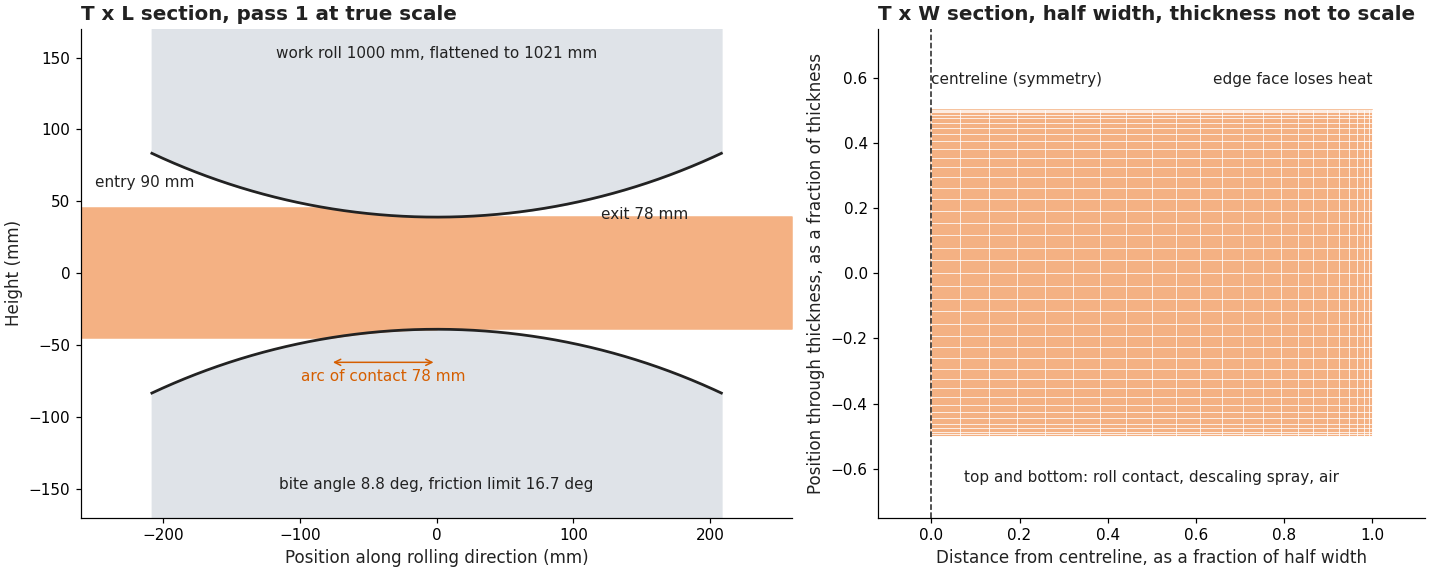

In [16]:
ps0, geo0 = PS[0], PS[0]["geo"]
Rp, Ld = ps0["Rp"], geo0["x"][0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1.3, 1]), constrained_layout=True)

th = np.linspace(-0.42, 0.42, 200)
for sgn in (1, -1):
    xr = Rp * np.sin(th)
    zr = sgn * (ps0["hf"] / 2 + Rp * (1 - np.cos(th)))
    a1.plot(xr, zr, color=INK, lw=1.8)
    a1.fill_between(xr, zr, sgn * 330, color="#dfe3e8", zorder=0)
xs = np.linspace(-Ld, Ld, 200)
hx = np.where(xs < 0, ps0["hf"] + (xs ** 2) / Rp, ps0["hf"])
a1.fill_between([-260, -Ld], -ps0["h0"] / 2, ps0["h0"] / 2, color="#f4b183")
a1.fill_between(np.linspace(-Ld, 0, 80), -(ps0["hf"] + np.linspace(-Ld, 0, 80) ** 2 / Rp) / 2, (ps0["hf"] + np.linspace(-Ld, 0, 80) ** 2 / Rp) / 2, color="#f4b183")
a1.fill_between([0, 260], -ps0["hf"] / 2, ps0["hf"] / 2, color="#f4b183")
a1.annotate("", xy=(-Ld, -62), xytext=(0, -62), arrowprops=dict(arrowstyle="<->", color=ACCENT))
a1.text(-Ld / 2, -75, f"arc of contact {Ld:.0f} mm", ha="center", color=ACCENT, fontsize=10)
a1.text(-250, 60, f"entry {ps0['h0']:.0f} mm", fontsize=10)
a1.text(120, 38, f"exit {ps0['hf']:.0f} mm", fontsize=10)
a1.text(0, 150, f"work roll {ps0['D_wr']:.0f} mm, flattened to {2 * Rp:.0f} mm", ha="center", fontsize=10)
a1.text(0, -150, f"bite angle {np.degrees(np.arccos(1 - ps0['dh'] / (2 * Rp))):.1f} deg, friction limit {np.degrees(np.arctan(P['mu'])):.1f} deg", ha="center", fontsize=10)
a1.set_xlim(-260, 260)
a1.set_ylim(-170, 170)
a1.set_xlabel("Position along rolling direction (mm)")
a1.set_ylabel("Height (mm)")
a1.set_title("T x L section, pass 1 at true scale")
a1.grid(False)

hh = ps0["h0"]
ycl = yfrac_nodes = np.sin(np.pi * np.arange(NY) / (2 * (NY - 1)))
a2.add_patch(plt.Rectangle((0, -0.5), 1, 1, color="#f4b183"))
for yv in ycl:
    a2.plot([yv, yv], [-0.5, 0.5], color="white", lw=0.5)
for zv in G.xi:
    a2.plot([0, 1], [zv, zv], color="white", lw=0.5)
a2.axvline(0, color=INK, ls="--", lw=1)
a2.set_xlim(-0.12, 1.12)
a2.set_ylim(-0.75, 0.75)
a2.set_xlabel("Distance from centreline, as a fraction of half width")
a2.set_ylabel("Position through thickness, as a fraction of thickness")
a2.set_title("T x W section, half width, thickness not to scale")
a2.text(0.0, 0.58, "centreline (symmetry)", fontsize=10)
a2.text(1.0, 0.58, "edge face loses heat", fontsize=10, ha="right")
a2.text(0.5, -0.64, "top and bottom: roll contact, descaling spray, air", ha="center", fontsize=10)
a2.grid(False)
plt.show()

In the left panel the plate narrows inside the arc and the two rolls touch it only over a short distance compared with the roll size. That ratio of arc length to thickness decides how deep the deformation penetrates, and we come back to it in the bite section. In the right panel the nodes crowd toward both faces and toward the edge, the three places where the temperature changes fastest. The dashed line is the plane of symmetry, where no heat crosses.

## The pass schedule

We next look at what the six inputs turn into. For each pass we want the draft and the reduction, the arc of contact, the bite angle against the friction limit, the flattened roll radius, the forward slip and the plate length after the pass. The bars on the right show how close each pass runs to the bite limit: a ratio of 1 means the roll would no longer grip the plate.

,direction,h_in,h_out,draft,reduction_pct,strain,strain_rate,arc_mm,bite_deg,bite_ratio,R_flat,slip_pct,contact_ms,width_out,length_out_m,T_in,force_MT,torque_kNm,power_kW,gap_set
pass_no,,,,,,,,,,,,,,,,,,,,
1,forward,90.0,78.0,12.0,13.33,0.17,5.17,78.04,8.79,0.52,510.56,2.60,31.98,2410.41,4.60,990.00,2832.78,2203.85,11019.24,74.91
2,reverse,78.0,67.0,11.0,14.10,0.18,5.70,74.82,8.41,0.49,511.72,2.58,30.77,2421.02,5.33,977.54,3223.16,2419.35,12096.77,63.49
3,forward,67.0,57.0,10.0,14.93,0.19,6.34,71.45,8.01,0.47,513.04,2.73,29.45,2431.82,6.23,965.07,3180.35,2230.98,11154.89,53.53
4,reverse,57.0,48.0,9.0,15.79,0.20,7.07,67.90,7.58,0.44,514.54,2.88,28.05,2442.75,7.37,950.47,3385.43,2262.09,11310.46,44.31
5,forward,48.0,40.0,8.0,16.67,0.21,7.93,64.15,7.14,0.42,516.36,3.12,26.54,2453.71,8.80,933.27,3396.51,2118.19,10590.94,36.30
6,reverse,40.0,34.0,6.0,15.00,0.19,9.28,55.76,6.16,0.36,519.61,2.98,20.23,2462.24,10.32,912.23,3274.78,1787.77,10130.71,30.43
7,forward,34.0,30.0,4.0,11.76,0.14,7.75,45.72,5.01,0.29,523.53,2.43,18.65,2467.64,11.67,886.78,2768.66,1244.13,6220.65,26.98


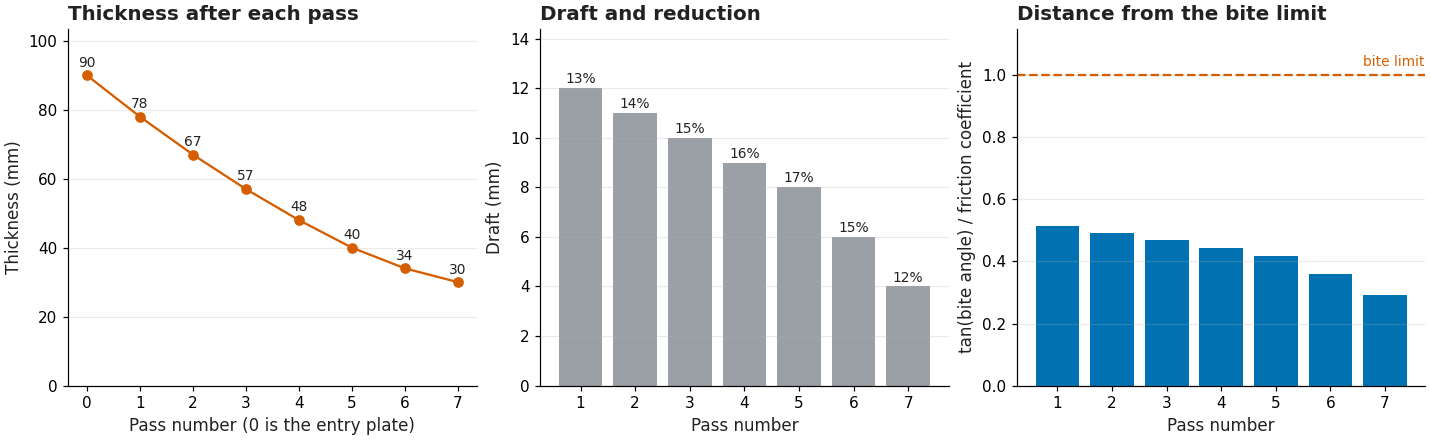

In [17]:
rows = []
for ps, pr in zip(PS, PR):
    Ld_k = ps["geo"]["x"][0]
    alpha_k = np.arccos(1 - ps["dh"] / (2 * ps["Rp"]))
    eps_m = 2 / np.sqrt(3) * np.log(ps["h0"] / ps["hf"])
    rows.append(dict(
        pass_no=ps["k"], direction="forward" if ps["fwd"] else "reverse",
        h_in=ps["h0"], h_out=ps["hf"], draft=ps["dh"], reduction_pct=100 * ps["dh"] / ps["h0"],
        strain=eps_m, strain_rate=eps_m / ps["tau"], arc_mm=Ld_k, bite_deg=np.degrees(alpha_k),
        bite_ratio=np.tan(alpha_k) / P["mu"], R_flat=ps["Rp"], slip_pct=100 * ps["f_slip"],
        contact_ms=1000 * ps["tau"], width_out=ps["Wf"], length_out_m=ps["Lf"] / 1000,
        T_in=G.mean(pr["TLin"])[CM], force_MT=pr["FL"][CM], torque_kNm=pr["torque"] / 1e3,
        power_kW=pr["power"], gap_set=pr["gap"],
    ))
SCHED = pd.DataFrame(rows).set_index("pass_no")
display(SCHED.round(2))

fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
ks = SCHED.index.values
th_line = [H0] + list(SCHED["h_out"])
ax[0].plot(range(0, N + 1), th_line, "-o", color=ACCENT)
for i, v in enumerate(th_line):
    ax[0].text(i, v + 2.5, f"{v:.0f}", ha="center", fontsize=9)
ax[0].set_xlabel("Pass number (0 is the entry plate)")
ax[0].set_ylabel("Thickness (mm)")
ax[0].set_title("Thickness after each pass")
ax[0].set_ylim(0, H0 * 1.15)
ax[1].bar(ks, SCHED["draft"], color=MUTED)
for k_, d_, r_ in zip(ks, SCHED["draft"], SCHED["reduction_pct"]):
    ax[1].text(k_, d_ + 0.2, f"{r_:.0f}%", ha="center", fontsize=9)
ax[1].set_xlabel("Pass number")
ax[1].set_ylabel("Draft (mm)")
ax[1].set_title("Draft and reduction")
ax[1].set_ylim(0, SCHED["draft"].max() * 1.2)
ax[2].bar(ks, SCHED["bite_ratio"], color=PALETTE[0])
ax[2].axhline(1, color=ACCENT, ls="--")
ax[2].text(N - 0.4, 1.02, "bite limit", color=ACCENT, va="bottom", fontsize=9, clip_on=False)
ax[2].set_xlabel("Pass number")
ax[2].set_ylabel("tan(bite angle) / friction coefficient")
ax[2].set_title("Distance from the bite limit")
ax[2].set_ylim(0, 1.15)
plt.show()

The left panel is the thickness ladder, ending at the final plate gauge. The middle panel shows the drafts with their percentage reduction on top. The right panel is the margin to the bite condition: every pass sits well below the dashed line, so the roll grips the plate with a comfortable margin at this friction coefficient. If we enter a heavy draft or a smaller roll, this is the first chart where a bar would cross the line.

In [18]:
lim_k = np.array([P["mu"] ** 2 * p["Rp"] for p in PS])
lim = float(lim_k.min())
tot_red = 100 * (H0 - PS[-1]["hf"]) / H0
display(Markdown(
    f"Total reduction is {tot_red:.0f}% from {H0:.0f} mm to {PS[-1]['hf']:.0f} mm. "
    f"The plate grows from {L0 / 1000:.1f} m to {PS[-1]['Lf'] / 1000:.1f} m and from {W0:.0f} mm to {PS[-1]['Wf']:.0f} mm wide by lateral spread. "
    f"The heaviest draft is {SCHED['draft'].max():.0f} mm, and the tightest bite limit in the "
    f"schedule is {lim:.0f} mm (pass {int(np.argmin(lim_k)) + 1}) for mu = {P['mu']}."
))

Total reduction is 67% from 90 mm to 30 mm. The plate grows from 4.0 m to 11.7 m and from 2400 mm to 2468 mm wide by lateral spread. The heaviest draft is 12 mm, and the tightest bite limit in the schedule is 46 mm (pass 1) for mu = 0.3.

## Material behaviour the model relies on

Two curves decide most of what follows. The first is the flow stress, which sets the roll force. The second is the half time for static recrystallization, which decides whether the austenite softens between passes. We plot both before using them. In the right panel the shaded band is the range of interpass waiting times in this schedule, and the vertical line is the non-recrystallization temperature from the chemistry.

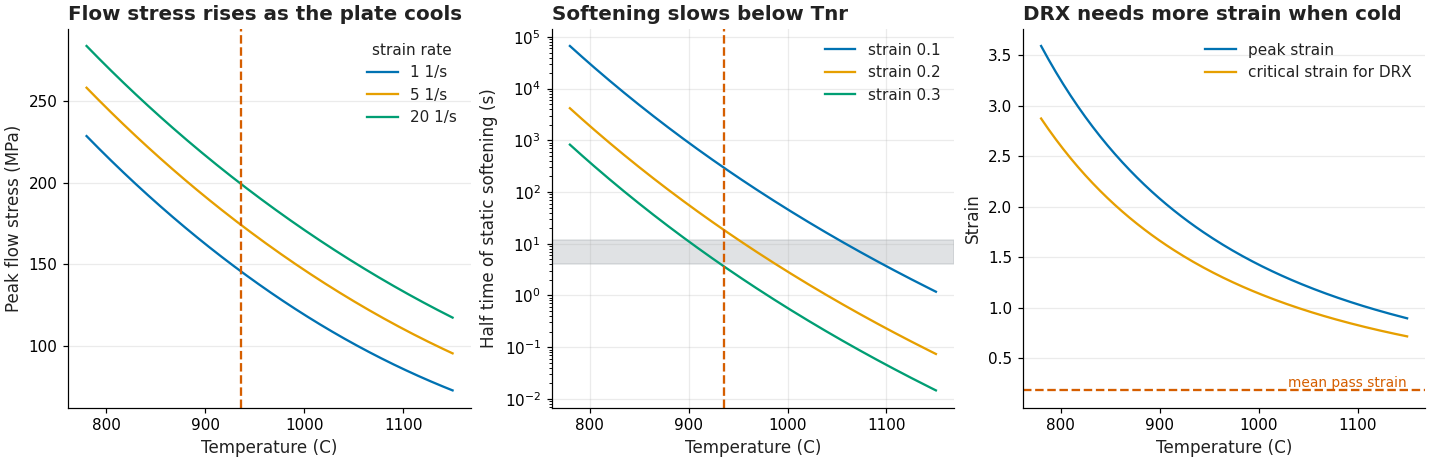

In [19]:
Tscan = np.linspace(780, 1150, 150)
TK = Tscan + 273.15
waits = np.concatenate([(PS[k + 1]["t_in"] - PS[k]["t_out"]) for k in range(N - 1)])

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
for i, rate in enumerate([1.0, 5.0, 20.0]):
    Z = rate * np.exp(P["Q"] / (R_GAS * TK))
    sp_ = np.arcsinh((Z / P["A"]) ** (1 / P["n_st"])) / P["alpha"]
    ax[0].plot(Tscan, sp_, color=PALETTE[i], label=f"{rate:g} 1/s")
ax[0].axvline(TNR, color=ACCENT, ls="--")
ax[0].legend(title="strain rate", frameon=False)
ax[0].set_xlabel("Temperature (C)")
ax[0].set_ylabel("Peak flow stress (MPa)")
ax[0].set_title("Flow stress rises as the plate cools")

for i, eps in enumerate([0.10, 0.20, 0.30]):
    t05 = (2.5e-19 * eps ** -4 * 60.0 ** 2 * np.exp(300000 / (R_GAS * TK)) * np.exp((2.75e5 / TK - 185) * P["chem"]["Nb"]))
    ax[1].semilogy(Tscan, t05, color=PALETTE[i], label=f"strain {eps}")
ax[1].axhspan(waits.min(), waits.max(), color=MUTED, alpha=0.3)
ax[1].axvline(TNR, color=ACCENT, ls="--")
ax[1].legend(frameon=False, loc="upper right")
ax[1].set_xlabel("Temperature (C)")
ax[1].set_ylabel("Half time of static softening (s)")
ax[1].set_title("Softening slows below Tnr")
ax[1].grid(True, axis="both", alpha=0.25)

rate = 5.0
Z = rate * np.exp(P["Q"] / (R_GAS * TK))
ec_ = (P["ep_A"] * P["d0"] ** P["ep_d0_pow"] * Z ** P["ep_Z_pow"]
       * (1 + P["nb_drx"] * P["chem"]["Nb"]))
ep_ = ec_ / P["ep_c_over_p"]
ax[2].plot(Tscan, ep_, color=PALETTE[0], label="peak strain")
ax[2].plot(Tscan, ec_, color=PALETTE[1], label="critical strain for DRX")
ax[2].axhline(SCHED["strain"].mean(), color=ACCENT, ls="--")
ax[2].text(Tscan[-1], SCHED["strain"].mean(), "mean pass strain", color=ACCENT, ha="right", va="bottom", fontsize=9)
ax[2].legend(frameon=False, loc="upper right")
ax[2].set_xlabel("Temperature (C)")
ax[2].set_ylabel("Strain")
ax[2].set_title("DRX needs more strain when cold")
plt.show()

The left panel shows the usual picture: at the same strain rate the peak flow stress climbs steeply as the temperature falls, and that is the origin of the force increase in the late passes. The middle panel is the one that sorts passes into regimes. Where the half time sits below the grey band the plate softens fully between passes, where it sits inside the band the softening is partial, and where it sits above the band the strain is carried forward. The curves also show how strongly the half time depends on the strain, so a light draft softens far more slowly than a heavy one. The right panel says that the strain per pass has to exceed the dashed critical line before DRX can start, and Nb pushes that line up.

In [20]:
i_lo = np.argmin(np.abs(Tscan - TNR))
display(Markdown(
    f"The non-recrystallization temperature for this chemistry is {TNR:.0f} C. "
    f"Interpass waits in this schedule run from {waits.min():.1f} s to {waits.max():.1f} s. "
    f"Entering the schedule at {T_FIRST:.0f} C, the plate crosses Tnr at the core during pass "
    f"{next((k + 1 for k in range(N) if G.mean(PR[k]['TLin'])[CM] < TNR), 'none')}."
))

The non-recrystallization temperature for this chemistry is 936 C. Interpass waits in this schedule run from 4.0 s to 12.0 s. Entering the schedule at 990 C, the plate crosses Tnr at the core during pass 5.

## Penetration of deformation, one 0.05 mm step at a time

The first thing we want from the bite is how deep the deformation reaches. A long contact arc on a thin plate deforms the whole thickness. A short arc on a thick plate deforms a layer under each face and leaves the core behind. We measure this at every station of the arc: the penetration depth is the distance from the face at which the strain has fallen halfway between its surface value and its core value, and the penetration ratio is that depth divided by half the thickness. A ratio of 1 means the strain is already nearly uniform and has reached the core.

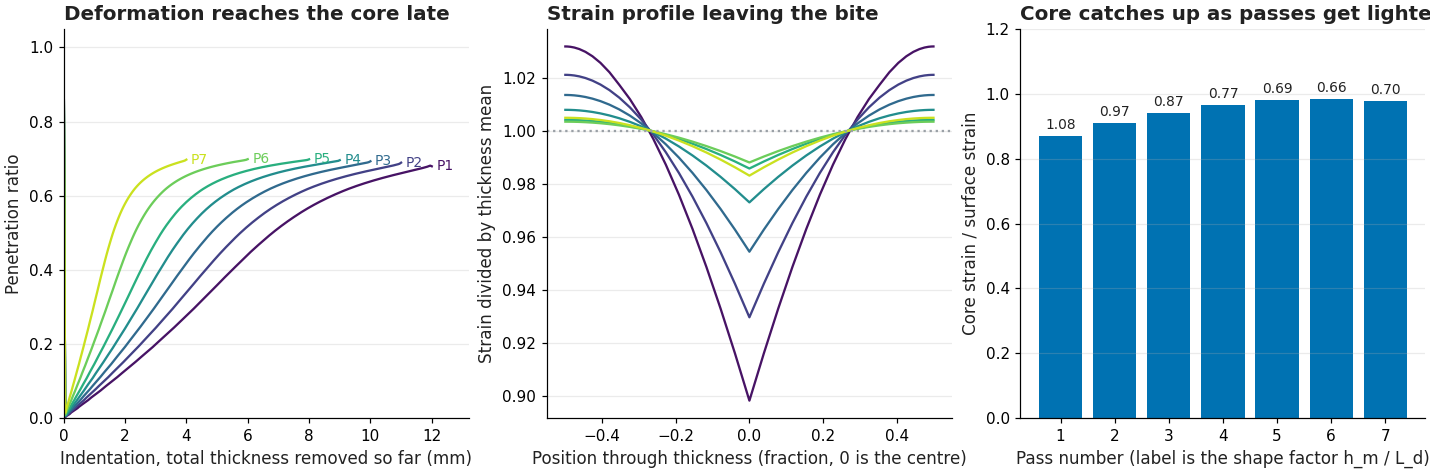

In [21]:
def penetration_ratio(eps_prof, h, xi):
    e = eps_prof[: len(xi) // 2 + 1]
    if e[0] <= 1e-9 or (e[0] - e[-1]) < 0.003 * e[0]:
        return 1.0
    half = 0.5 * (e[0] + e[-1])
    s = h * (0.5 + xi[: len(xi) // 2 + 1])
    below = np.where(e < half)[0]
    if len(below) == 0:
        return 1.0
    j = below[0]
    d = s[j - 1] + (half - e[j - 1]) * (s[j] - s[j - 1]) / (e[j] - e[j - 1])
    return min(d / (h / 2), 1.0)

PEN = []
for ps, pr in zip(PS, PR):
    rec = pr["oL"]["rec"]
    h = ps["geo"]["h"]
    ep0 = rec["eps"][0]
    PEN.append(np.array([penetration_ratio(rec["eps"][i] - ep0, h[i], G.xi) for i in range(len(h))]))

fig, ax = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True)
for k in range(N):
    ind = np.arange(len(PEN[k])) * PS[k]["dh"] / (len(PEN[k]) - 1)
    ax[0].plot(ind, PEN[k], color=PCOL[k])
    ax[0].text(ind[-1] + 0.15, PEN[k][-1], f"P{k + 1}", color=PCOL[k], fontsize=9, va="center", clip_on=False)
ax[0].set_xlabel("Indentation, total thickness removed so far (mm)")
ax[0].set_ylabel("Penetration ratio")
ax[0].set_title("Deformation reaches the core late")
ax[0].set_ylim(0, 1.05)
ax[0].set_xlim(0, max(p["dh"] for p in PS) * 1.1)

for k in range(N):
    ps = PS[k]
    prof = PR[k]["oL"]["rec"]["eps"][-1] - PR[k]["oL"]["rec"]["eps"][0]
    ax[1].plot(G.xi, prof / prof.mean(), color=PCOL[k])
ax[1].axhline(1, color=MUTED, ls=":")
ax[1].set_xlabel("Position through thickness (fraction, 0 is the centre)")
ax[1].set_ylabel("Strain divided by thickness mean")
ax[1].set_title("Strain profile leaving the bite")

ratio = [(PR[k]["oL"]["eps_pass"][IC] / PR[k]["oL"]["eps_pass"][0]) for k in range(N)]
ax[2].bar(range(1, N + 1), ratio, color=PALETTE[0])
for k in range(N):
    ax[2].text(k + 1, ratio[k] + 0.02, f"{PR[k]['oL']['Delta']:.2f}", ha="center", fontsize=9)
ax[2].set_ylim(0, 1.2)
ax[2].set_xlabel("Pass number (label is the shape factor h_m / L_d)")
ax[2].set_ylabel("Core strain / surface strain")
ax[2].set_title("Core catches up as passes get lighter")
plt.show()

In the left panel every curve starts near zero, because the first 0.05 mm of indentation only touches the face, and rises as the roll bites deeper. A curve that reaches 1 before the end of the arc means the deformation went through the full thickness. In the middle panel a flat line at 1 would be perfectly homogeneous deformation, and the bend away from 1 near the faces is the surface-heavy strain. The right panel uses the shape factor printed above each bar. Large values of $h_m/L_d$ mean a thick plate under a short arc, and those passes leave the core with less strain.

In [22]:
cr = [ratio[k] for k in range(N)]
full = [k + 1 for k in range(N) if PEN[k][-1] >= 0.999]
core_txt = ("passes " + ", ".join(str(k) for k in full)) if full else f"none of the {N} passes"
display(Markdown(
    f"Core strain ranges from {min(cr):.2f} to {max(cr):.2f} of the surface strain. "
    f"The deformation front reaches the core by the end of the arc in {core_txt}. "
    f"The shape factor runs from {min(p['oL']['Delta'] for p in PR):.2f} in pass {int(np.argmin([p['oL']['Delta'] for p in PR])) + 1} "
    f"to {max(p['oL']['Delta'] for p in PR):.2f} in pass {int(np.argmax([p['oL']['Delta'] for p in PR])) + 1}."
))

Core strain ranges from 0.87 to 0.98 of the surface strain. The deformation front reaches the core by the end of the arc in none of the 7 passes. The shape factor runs from 0.66 in pass 6 to 1.08 in pass 1.

## Watching the bite in T x L

Now we replay the bite. Each frame is one stage of the penetration: the roll has moved a few more 0.05 mm steps into the plate, and the revealed part of the wedge shows what the material has experienced so far. The left panel is the strain accumulated within the pass, the middle panel is the temperature, and the right panel is the roll pressure along the arc together with the plane-strain yield stress $k'$. The gap between the two curves is the friction hill. The dashed line marks the neutral point. Use the slider or the play button; the label gives the pass and the thickness removed so far.

Under the interactive figure are five stills of the same walk through pass 1, drawn as plain images. The frame by frame picture is there whatever the viewer does with the animation's script, and the animation is also written to `rolling_outputs/bite_TxL.html`, which plays in a browser.


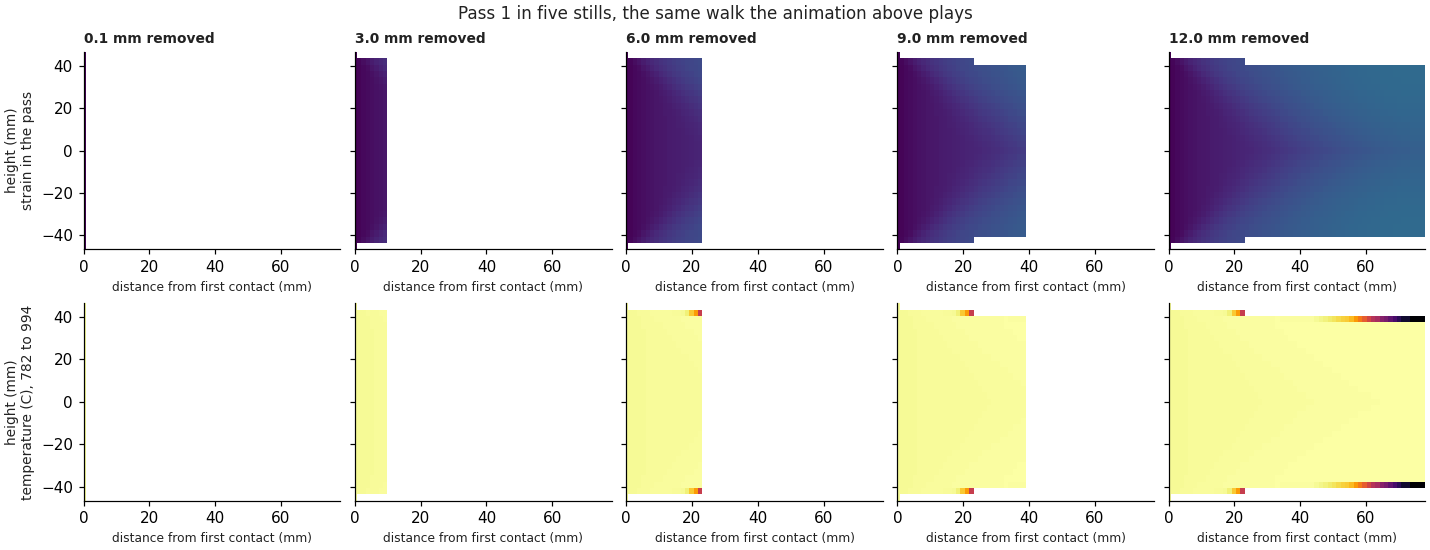

In [23]:
def wedge_grid(rec, geo, xi, nu=24, nzg=13):
    h, x = geo["h"], geo["x"]
    Ld_ = x[0]
    u_st = Ld_ - x
    ug = np.linspace(0, Ld_, nu)
    zg = np.linspace(-h[0] / 2, h[0] / 2, nzg)
    j = np.clip(np.searchsorted(u_st, ug), 0, len(h) - 1)
    E = np.full((nu, nzg), np.nan)
    T_ = E.copy()
    for a, jj in enumerate(j):
        xin = zg / h[jj]
        ins = np.abs(xin) <= 0.5
        E[a, ins] = np.interp(xin[ins], xi, rec["eps"][jj] - rec["eps"][0])
        T_[a, ins] = np.interp(xin[ins], xi, rec["T"][jj])
    return ug, zg, E, T_, h[j], u_st

nfr = RES["nfr"]
allE = [pr["oL"]["rec"]["eps"][-1].max() - pr["oL"]["rec"]["eps"][0].min() for pr in PR]
Tmin = min(pr["oL"]["rec"]["T"].min() for pr in PR)
Tmax = max(pr["oL"]["rec"]["T"].max() for pr in PR)
pmax = max(pr["oL"]["p"][CM].max() for pr in PR)
frames, names, labels = [], [], []
for k in range(N):
    ps, pr = PS[k], PR[k]
    rec = pr["oL"]["rec"]
    geo = ps["geo"]
    ug, zg, E, T_, hu, u_st = wedge_grid(rec, geo, G.xi)
    n = len(geo["h"]) - 1
    p_ = pr["oL"]["p"][CM]
    kp_ = pr["oL"]["kp"][CM]
    nn = pr["oL"]["nn"][CM]
    for i in np.linspace(1, n, nfr).astype(int):
        uf = u_st[i]
        mE = np.where(ug[:, None] <= uf, E, np.nan)
        mT = np.where(ug[:, None] <= uf, T_, np.nan)
        pm = np.where(u_st <= uf, p_, np.nan)
        km = np.where(u_st <= uf, kp_, np.nan)
        nm = f"P{k + 1}_{i}"
        frames.append(go.Frame(name=nm, traces=list(range(9)), data=[
            go.Heatmap(x=ug, y=zg, z=np.round(mE.T, 2), zmin=0, zmax=max(allE), colorscale="Viridis", showscale=False),
            go.Heatmap(x=ug, y=zg, z=np.round(mT.T, 0), zmin=Tmin, zmax=Tmax, colorscale="Inferno", showscale=False),
            go.Scatter(x=ug, y=hu / 2, mode="lines", line=dict(color="black", width=2)),
            go.Scatter(x=ug, y=-hu / 2, mode="lines", line=dict(color="black", width=2)),
            go.Scatter(x=ug, y=hu / 2, mode="lines", line=dict(color="black", width=2)),
            go.Scatter(x=ug, y=-hu / 2, mode="lines", line=dict(color="black", width=2)),
            go.Scatter(x=u_st[::3], y=np.round(pm[::3], 1), mode="lines", line=dict(color=ACCENT, width=3)),
            go.Scatter(x=u_st[::3], y=np.round(km[::3], 1), mode="lines", line=dict(color=PALETTE[0], width=2, dash="dot")),
            go.Scatter(x=[u_st[nn], u_st[nn]], y=[0, pmax * 1.05], mode="lines", line=dict(color=INK, width=1, dash="dash")),
        ], layout=go.Layout(
            xaxis=dict(range=[0, geo["x"][0]]), xaxis2=dict(range=[0, geo["x"][0]]), xaxis3=dict(range=[0, geo["x"][0]]),
            yaxis=dict(range=[-ps["h0"] / 2 * 1.08, ps["h0"] / 2 * 1.08]), yaxis2=dict(range=[-ps["h0"] / 2 * 1.08, ps["h0"] / 2 * 1.08]),
        )))
        names.append(nm)
        labels.append(f"P{k + 1} {i * ps['dh'] / n:.2f} mm")

fig = make_subplots(rows=1, cols=3, subplot_titles=("Strain in the pass", "Temperature (C)", "Roll pressure and yield stress (MPa)"), horizontal_spacing=0.07)
f0 = frames[0].data
fig.add_trace(go.Heatmap(f0[0], colorbar=dict(x=0.31, len=0.8, thickness=10, title="strain")), row=1, col=1)
fig.add_trace(go.Heatmap(f0[1], colorbar=dict(x=0.65, len=0.8, thickness=10, title="C")), row=1, col=2)
for tr, c in zip(f0[2:], [1, 1, 2, 2, 3, 3, 3]):
    fig.add_trace(tr, row=1, col=c)
fig.update_xaxes(title_text="Distance from first contact (mm)")
fig.update_yaxes(title_text="Height (mm)", row=1, col=1)
fig.update_yaxes(range=[0, pmax * 1.1], row=1, col=3)
fig.update_layout(
    height=520, showlegend=False, margin=dict(l=60, r=30, t=70, b=150),
    updatemenus=[dict(type="buttons", x=0.0, y=-0.19, direction="left", buttons=[
        dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=90, redraw=True), fromcurrent=True)]),
        dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
    sliders=[dict(x=0.2, len=0.8, y=-0.19, currentvalue=dict(prefix="Frame: "), steps=[
        dict(method="animate", label=lb, args=[[nm], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for nm, lb in zip(names, labels)])],
)
fig.frames = frames
slim(fig)
fig.write_html("rolling_outputs/bite_TxL.html", include_plotlyjs="cdn")
fig.show()

# the same walk as five stills, so the picture is here even if the interactive one is refused
ps_s, pr_s = PS[0], PR[0]
geo_s = ps_s["geo"]
n_s = len(geo_s["h"]) - 1
ug_s, zg_s, E_s, T_s, hu_s, u_st_s = wedge_grid(pr_s["oL"]["rec"], geo_s, G.xi, nu=60, nzg=31)
T_lo_s, T_hi_s = span_of(T_s, (Tmin, Tmax))
fig, axs = plt.subplots(2, 5, figsize=(13.0, 5.0), constrained_layout=True, squeeze=False, sharey=True)
for c, i in enumerate(np.unique(np.linspace(1, n_s, 5).astype(int))):
    uf = u_st_s[i]
    axs[0, c].pcolormesh(ug_s, zg_s, np.where(ug_s[:, None] <= uf, E_s, np.nan).T,
                         cmap="viridis", shading="auto", vmin=0, vmax=max(allE), rasterized=True)
    axs[1, c].pcolormesh(ug_s, zg_s, np.where(ug_s[:, None] <= uf, T_s, np.nan).T,
                         cmap="inferno", shading="auto", vmin=T_lo_s, vmax=T_hi_s, rasterized=True)
    axs[0, c].set_title(f"{i * ps_s['dh'] / n_s:.1f} mm removed", fontsize=9)
    for r_ in (0, 1):
        axs[r_, c].set_xlabel("distance from first contact (mm)", fontsize=8)
        axs[r_, c].set_xlim(0, geo_s["x"][0])
        axs[r_, c].grid(False)
axs[0, 0].set_ylabel("height (mm)\nstrain in the pass", fontsize=9)
axs[1, 0].set_ylabel(f"height (mm)\ntemperature (C), {T_lo_s:.0f} to {T_hi_s:.0f}", fontsize=9)
fig.suptitle("Pass 1 in five stills, the same walk the animation above plays", fontsize=11)
plt.show()


In the first frames of every pass only a thin sliver at the entry is coloured, and the strain is concentrated under the faces. As the front advances, the colour spreads toward the core, which is the penetration we measured above. In the temperature panel the faces turn dark within a few steps because the roll chills a skin of a fraction of a millimetre, while the interior brightens slightly from adiabatic heating. On the right the pressure curve rises on both sides of the neutral point, forming the friction hill, and stays above the yield stress curve everywhere. Heavier drafts and colder passes lift the whole hill.

In [24]:
k_hot = int(np.argmax([pr["oL"]["p"][CM].max() for pr in PR]))
display(Markdown(
    f"Peak roll pressure is {pmax:.0f} MPa, reached in pass {k_hot + 1}. "
    f"The neutral point sits {100 * PR[k_hot]['oL']['nn_x'][CM] / PS[k_hot]['geo']['x'][0]:.0f}% of the arc length back from the exit plane in that pass. "
    f"Surface skin temperature after the roll contact drops to {min(pr['oL']['rec']['T'][-1][0] for pr in PR):.0f} C at the coldest pass."
))

Peak roll pressure is 298 MPa, reached in pass 7. The neutral point sits 45% of the arc length back from the exit plane in that pass. Surface skin temperature after the roll contact drops to 603 C at the coldest pass.

## Watching the bite in T x W

The same march through the arc looks different in the cross-section. The plate is cut across its width, and every frame shows how that section changes as it travels through the bite. The left panel is the strain, the middle panel is the temperature, and the right panel is the force per unit width that has built up so far, in MN per metre. Edges are cooler than the centre because they lose heat from the side face, so the edge material is stiffer and the force intensity rises toward the edge. The thickness axis is exaggerated against the width.

Under the interactive figure are five stills of the same cross section through pass 1, drawn as plain images. The frame by frame picture is there whatever the viewer does with the animation's script, and the animation is also written to `rolling_outputs/bite_TxW.html`, which plays in a browser.


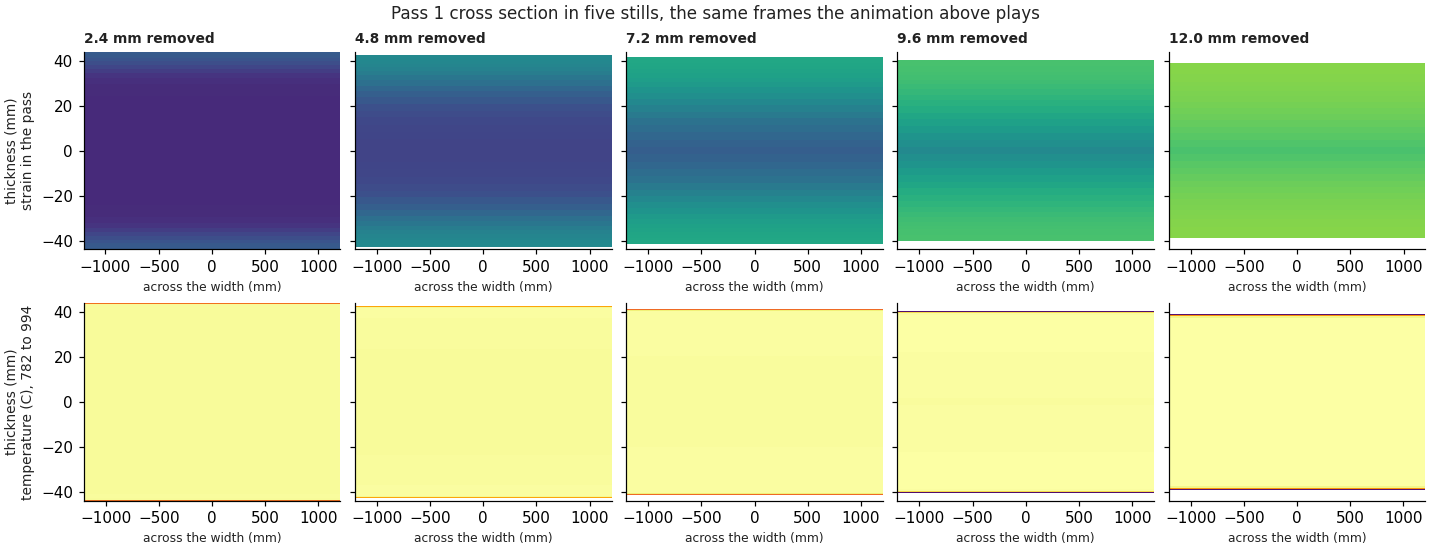

In [25]:
def mirror(a):
    return np.concatenate([a[:0:-1], a], axis=0)

yf_ = S["yfrac"]
wsel = slice(None, None, 3)     # width nodes kept in the animated frames
zsel = slice(None, None, 3)     # thickness nodes kept in the animated frames
frames2, names2, labels2 = [], [], []
allEW = max((pr["oW"]["recs"][max(pr["oW"]["recs"])]["eps"] - pr["oW"]["recs"][0]["eps"]).max() for pr in PR)
TWmin = min(r["T"].min() for pr in PR for r in pr["oW"]["recs"].values())
TWmax = max(r["T"].max() for pr in PR for r in pr["oW"]["recs"].values())
for k in range(N):
    ps, pr = PS[k], PR[k]
    x_ = ps["geo"]["x"]
    p_ = pr["oW"]["p"]
    cum = np.concatenate([np.zeros((p_.shape[0], 1)), np.cumsum(0.5 * (p_[:, 1:] + p_[:, :-1]) * np.abs(np.diff(x_))[None, :], axis=1)], axis=1) / 1000
    ymm = np.concatenate([-yf_[::3][:0:-1], yf_[::3]]) * ps["Wf"] / 2
    n = len(ps["geo"]["h"]) - 1
    e0 = pr["oW"]["recs"][0]["eps"]
    for i in sorted(pr["oW"]["recs"]):
        if i == 0:
            continue
        r = pr["oW"]["recs"][i]
        zmm = (G.xi * ps["geo"]["h"][i])[zsel]
        nm = f"W{k + 1}_{i}"
        frames2.append(go.Frame(name=nm, traces=[0, 1, 2], data=[
            go.Heatmap(x=ymm, y=zmm, z=np.round(mirror((r["eps"] - e0)[wsel][:, zsel]).T, 2), zmin=0, zmax=allEW, colorscale="Viridis", showscale=False),
            go.Heatmap(x=ymm, y=zmm, z=np.round(mirror(r["T"][wsel][:, zsel]).T, 0), zmin=TWmin, zmax=TWmax, colorscale="Inferno", showscale=False),
            go.Scatter(x=ymm, y=np.round(mirror(cum[wsel, i]), 2), mode="lines", line=dict(color=ACCENT, width=3)),
        ], layout=go.Layout(
            xaxis=dict(range=[-ps["Wf"] / 2, ps["Wf"] / 2]), xaxis2=dict(range=[-ps["Wf"] / 2, ps["Wf"] / 2]), xaxis3=dict(range=[-ps["Wf"] / 2, ps["Wf"] / 2]),
            yaxis=dict(range=[-ps["h0"] / 2 * 1.05, ps["h0"] / 2 * 1.05]), yaxis2=dict(range=[-ps["h0"] / 2 * 1.05, ps["h0"] / 2 * 1.05]))))
        names2.append(nm)
        labels2.append(f"P{k + 1} {i * ps['dh'] / n:.2f} mm")

fig = make_subplots(rows=1, cols=3, subplot_titles=("Strain in the pass", "Temperature (C)", "Force per width so far (MN/m)"), horizontal_spacing=0.07)
f0 = frames2[0].data
fig.add_trace(go.Heatmap(f0[0], colorbar=dict(x=0.31, len=0.8, thickness=10, title="strain")), row=1, col=1)
fig.add_trace(go.Heatmap(f0[1], colorbar=dict(x=0.65, len=0.8, thickness=10, title="C")), row=1, col=2)
fig.add_trace(f0[2], row=1, col=3)
fig.update_xaxes(title_text="Across the width (mm)")
fig.update_yaxes(title_text="Thickness (mm)", row=1, col=1)
fig.update_yaxes(range=[0, 1.05 * max(np.abs(TRAPZ(pr["oW"]["p"], PS[k]["geo"]["x"], axis=1)).max() for k, pr in enumerate(PR)) / 1000], row=1, col=3)
fig.update_layout(
    height=520, showlegend=False, margin=dict(l=60, r=30, t=70, b=150),
    updatemenus=[dict(type="buttons", x=0.0, y=-0.19, direction="left", buttons=[
        dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=90, redraw=True), fromcurrent=True)]),
        dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
    sliders=[dict(x=0.2, len=0.8, y=-0.19, currentvalue=dict(prefix="Frame: "), steps=[
        dict(method="animate", label=lb, args=[[nm], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for nm, lb in zip(names2, labels2)])],
)
fig.frames = frames2
slim(fig)
fig.write_html("rolling_outputs/bite_TxW.html", include_plotlyjs="cdn")
fig.show()

# the same cross section as five stills
ps_s, pr_s = PS[0], PR[0]
recs_s = pr_s["oW"]["recs"]
n_s = len(ps_s["geo"]["h"]) - 1
e0_s = recs_s[0]["eps"]
ymm_s = np.concatenate([-yf_[:0:-1], yf_]) * ps_s["Wf"] / 2
ks_s = sorted(i for i in recs_s if i != 0)
pick_s = [ks_s[min(int(q), len(ks_s) - 1)] for q in np.linspace(0, len(ks_s) - 1, 5)]
panels_s = [(i, G.xi * ps_s["geo"]["h"][i], mirror(recs_s[i]["eps"] - e0_s),
             mirror(recs_s[i]["T"])) for i in pick_s]
T_lo_s = min(span_of(p[3], (TWmin, TWmax))[0] for p in panels_s)
T_hi_s = max(span_of(p[3], (TWmin, TWmax))[1] for p in panels_s)
fig, axs = plt.subplots(2, 5, figsize=(13.0, 5.0), constrained_layout=True, squeeze=False, sharey=True)
for c, (i, zmm_s, dE_s, dT_s) in enumerate(panels_s):
    axs[0, c].pcolormesh(ymm_s, zmm_s, dE_s.T, cmap="viridis", shading="auto",
                         vmin=0, vmax=allEW, rasterized=True)
    axs[1, c].pcolormesh(ymm_s, zmm_s, dT_s.T, cmap="inferno", shading="auto",
                         vmin=T_lo_s, vmax=T_hi_s, rasterized=True)
    axs[0, c].set_title(f"{i * ps_s['dh'] / n_s:.1f} mm removed", fontsize=9)
    axs[0, c].set_xlim(-ps_s["Wf"] / 2, ps_s["Wf"] / 2)
    for r2 in (0, 1):
        axs[r2, c].set_xlabel("across the width (mm)", fontsize=8)
        axs[r2, c].grid(False)
axs[0, 0].set_ylabel("thickness (mm)\nstrain in the pass", fontsize=9)
axs[1, 0].set_ylabel(f"thickness (mm)\ntemperature (C), {T_lo_s:.0f} to {T_hi_s:.0f}", fontsize=9)
fig.suptitle("Pass 1 cross section in five stills, the same frames the animation above plays",
             fontsize=11)
plt.show()


At the start of each pass the cross-section is almost uniform in strain, and over the following frames the faces pull ahead of the core. The temperature panel shows the cold skin on the top and bottom and a slightly colder band at each edge that was already there when the pass began. In the right panel the force per unit width builds along the arc, and the curve is not flat across the width: the cooler edges carry more force per unit width than the centre.

In [26]:
edge_gain = [(pr["oW"]["Fp"][-1] / pr["oW"]["Fp"][0] - 1) * 100 for pr in PR]
display(Markdown(
    f"Force per unit width at the edge exceeds the centre by {min(edge_gain):.1f}% to {max(edge_gain):.1f}% across the passes, "
    f"with the largest difference in pass {int(np.argmax(edge_gain)) + 1}. "
    f"Edge temperature entering the passes is lower than the centre by {np.mean([pr['TWin'][0].mean() - pr['TWin'][-1].mean() for pr in PR]):.1f} C on average."
))

Force per unit width at the edge exceeds the centre by 0.0% to 17.0% across the passes, with the largest difference in pass 6. Edge temperature entering the passes is lower than the centre by 32.8 C on average.

## Roll pressure, force and power

We now turn to the von Karman solution. The pressure rises from the yield stress at the entry plane to a peak at the neutral point and falls back toward the exit. The area under that curve, multiplied by the plate width, is the roll force, and we report it in metric tonnes. The left panel shows the pressure along the arc of contact for every pass at mid-length, with a dot on the neutral point. The middle panel shows the force with a whisker for the range from the head to the tail of the plate. The right panel shows the drive power.

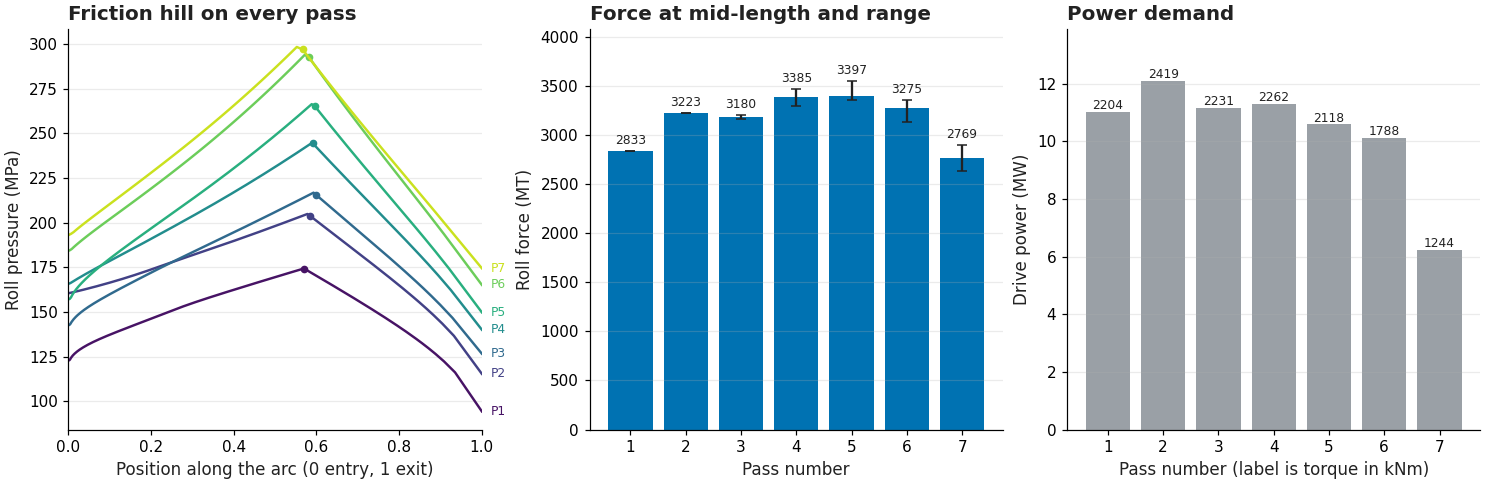

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.4), constrained_layout=True)
for k in range(N):
    x_ = PS[k]["geo"]["x"]
    u_ = 1 - x_ / x_[0]
    p_ = PR[k]["oL"]["p"][CM]
    nn = PR[k]["oL"]["nn"][CM]
    ax[0].plot(u_, p_, color=PCOL[k], lw=1.6)
    ax[0].plot(u_[nn], p_[nn], "o", color=PCOL[k], ms=4)
ax[0].set_xlabel("Position along the arc (0 entry, 1 exit)")
ax[0].set_ylabel("Roll pressure (MPa)")
ax[0].set_title("Friction hill on every pass")
ax[0].set_xlim(0, 1)
series_labels(ax[0], [(1.0, PR[k]["oL"]["p"][CM][-1], f"P{k + 1}", PCOL[k]) for k in range(N)])

fm = np.array([PR[k]["FL"][CM] for k in range(N)])
lo = np.array([PR[k]["FL"].min() for k in range(N)])
hi = np.array([PR[k]["FL"].max() for k in range(N)])
ax[1].bar(range(1, N + 1), fm, color=PALETTE[0], yerr=[fm - lo, hi - fm], capsize=3, ecolor=INK)
for k in range(N):
    ax[1].text(k + 1, hi[k] + 0.02 * hi.max(), f"{fm[k]:.0f}", ha="center", fontsize=8)
ax[1].set_xlabel("Pass number")
ax[1].set_ylabel("Roll force (MT)")
ax[1].set_title("Force at mid-length and range")
ax[1].set_ylim(0, hi.max() * 1.15)

pw = np.array([PR[k]["power"] for k in range(N)])
tq = np.array([PR[k]["torque"] / 1e3 for k in range(N)])
ax[2].bar(range(1, N + 1), pw / 1e3, color=MUTED)
for k in range(N):
    ax[2].text(k + 1, pw[k] / 1e3 + 0.1, f"{tq[k]:.0f}", ha="center", fontsize=8)
ax[2].set_xlabel("Pass number (label is torque in kNm)")
ax[2].set_ylabel("Drive power (MW)")
ax[2].set_title("Power demand")
ax[2].set_ylim(0, pw.max() / 1e3 * 1.15)
plt.show()

Every curve starts and ends at the plane-strain yield stress, climbs on both sides of the neutral point, and peaks at the neutral point itself, which is the point where the roll and plate surfaces move at the same speed. Heavier drafts raise the whole hill, and so does a colder plate. The whiskers in the middle panel show that the force is not constant along the plate: every length position meets the roll at its own temperature and with its own retained strain. The right panel gives the drive power, which follows the force and the arm of the pressure about the roll axis.

In [28]:
imax = int(np.argmax(fm))
gap = SCHED["gap_set"]
display(Markdown(
    f"Mid-length roll force runs from {fm.min():.0f} MT in pass {int(np.argmin(fm)) + 1} to {fm.max():.0f} MT in pass {imax + 1}. "
    f"Over the whole schedule the largest head to tail spread inside one pass is {(hi - lo).max():.0f} MT (pass {int(np.argmax(hi - lo)) + 1}). "
    f"Peak drive power is {pw.max() / 1e3:.1f} MW and peak torque is {tq.max():.0f} kNm. "
    f"With a mill modulus of {P['mill_modulus'] / 1e6:.0f} MN/mm, the roll gap must be set about {(SCHED['h_out'] - gap).max():.1f} mm below the target thickness on the heaviest pass."
))

Mid-length roll force runs from 2769 MT in pass 7 to 3397 MT in pass 5. Over the whole schedule the largest head to tail spread inside one pass is 270 MT (pass 7). Peak drive power is 12.1 MW and peak torque is 2419 kNm. With a mill modulus of 9 MN/mm, the roll gap must be set about 3.7 mm below the target thickness on the heaviest pass.

### Checking the bite solution

Before reading the force numbers, one test that does not need a mill measurement. The strip in
the bite has no front and no back tension, so the horizontal forces on it must cancel: the roll
pressure pushes the strip back toward the entry with a component proportional to the slope of the
arc, and the friction the rolls apply pulls it back the other way, in opposite directions on the
two sides of the neutral point. The two integrals below are therefore equal for any solution of
the equilibrium equations, and the residual measures how far the integrated pressure field is
from satisfying them. The mean pressure is also compared with the classical sliding and sticking
bounds, $\bar p/2k$ between $1 + \mu L_d/2\bar h$ and $1 + L_d/4\bar h$.


In [29]:
# ---- is the bite solution in equilibrium? -----------------------------------
# The strip in the bite carries no front or back tension, so its horizontal force balance closes
# exactly: the back push of the roll pressure over the whole arc equals the friction the rolls
# apply to the strip, entry side minus exit side, with the two sides split where the branches
# meet. Each column below is a property of the solution itself, so this doubles as a check on the
# von Karman integration.
def balance_residual(p, kp, x, phi, xn, mu, cap):
    """Residual of the strip's horizontal balance, in per cent, and the back push."""
    tau = np.minimum(mu * p, cap * kp)
    tau_n = float(np.interp(xn, x[::-1], tau[::-1]))
    entry_side, exit_side = x >= xn, x < xn
    fr_entry = 2 * abs(TRAPZ(np.r_[tau[entry_side], tau_n], np.r_[x[entry_side], xn]))
    fr_exit = 2 * abs(TRAPZ(np.r_[tau_n, tau[exit_side]], np.r_[xn, x[exit_side]]))
    back = 2 * abs(TRAPZ(p * np.tan(phi), x))
    return 100 * (back - (fr_entry - fr_exit)) / (fr_entry - fr_exit), back


rows = []
for ps, pr in zip(PS, PR):
    x, phi = ps["geo"]["x"], ps["geo"]["phi"]
    p, kp = pr["oL"]["p"][CM], pr["oL"]["kp"][CM]
    xn = float(pr["oL"]["nn_x"][CM])            # neutral point, mm measured from the exit plane
    res, _ = balance_residual(p, kp, x, phi, xn, P["mu"], P["shear_limit"] * P["tau_frac"])
    pbar = abs(TRAPZ(p, x)) / x[0]
    k2 = float(np.mean(kp))
    hm = 0.5 * (ps["h0"] + ps["hf"])
    rows.append(dict(pass_no=ps["k"], mean_pressure_MPa=pbar, mean_2k_MPa=k2, p_bar_over_2k=pbar / k2,
                     sliding_bound=1 + P["mu"] * x[0] / (2 * hm), sticking_bound=1 + x[0] / (4 * hm),
                     min_p_minus_2k_MPa=float(np.min(p - kp)),
                     neutral_pct_from_exit=100 * xn / x[0], balance_residual_pct=res))
CHK = pd.DataFrame(rows).set_index("pass_no")
display(CHK.round(3))

# What is left of that residual is the indentation step, because the hill is exponential and both
# branches are marched over the same steps. Refining the step on the heaviest pass shows it.
ps_ref, pr_ref = PS[0], PR[0]
refined = []
for step in (RES["step_mm"], 0.01):
    geo = dict(zip(["h", "phi", "x"],
                   pass_geometry(ps_ref["h0"], ps_ref["hf"], ps_ref["Rp"], step=step)))
    o = solve_pass(pr_ref["TLin"], np.zeros_like(pr_ref["TLin"]),
                   np.full_like(pr_ref["TLin"], P["d0"]), geo, P, G, ps_ref["vr"], ps_ref["vf"])
    r_ref, _ = balance_residual(o["p"][CM], o["kp"][CM], geo["x"], geo["phi"],
                                float(o["nn_x"][CM]), P["mu"], P["shear_limit"] * P["tau_frac"])
    refined.append((step, len(geo["h"]) - 1, abs(r_ref)))
display(Markdown(
    f"Mean roll pressure sits at {CHK['p_bar_over_2k'].min():.2f} to {CHK['p_bar_over_2k'].max():.2f} "
    f"times the plane strain yield stress, against the classical constant flow stress bounds of "
    f"{CHK['sliding_bound'].min():.2f} to {CHK['sticking_bound'].max():.2f} in the same table, and it "
    f"never falls more than {abs(CHK['min_p_minus_2k_MPa'].min()):.1f} MPa below the local yield "
    f"stress on any pass. The neutral point sits {CHK['neutral_pct_from_exit'].min():.0f} to "
    f"{CHK['neutral_pct_from_exit'].max():.0f}% of the arc length from the exit plane. The horizontal "
    f"force balance of the strip, with the friction split where the branches meet, is satisfied to "
    f"{refined[1][2]:.0f}% on the heaviest pass once the bite step is taken down to 0.01 mm "
    f"({refined[0][2]:.0f}% at the {RES['step_mm']:.2f} mm default), so what is left at the working "
    f"resolution is the quadrature of an exponential hill rather than a term missing from the equation."
))


,mean_pressure_MPa,mean_2k_MPa,p_bar_over_2k,sliding_bound,sticking_bound,min_p_minus_2k_MPa,neutral_pct_from_exit,balance_residual_pct
pass_no,,,,,,,,
1,147.675,137.286,1.076,1.139,1.232,-1.952,43.788,64.684
2,174.431,160.358,1.088,1.155,1.258,0.000,42.239,25.020
3,179.374,158.368,1.133,1.173,1.288,-0.253,40.711,13.291
4,199.923,173.267,1.154,1.194,1.323,0.000,42.116,26.127
5,211.367,176.665,1.196,1.219,1.364,-0.170,41.356,14.751
6,233.522,193.630,1.206,1.226,1.377,0.000,43.253,23.193
7,240.306,200.217,1.200,1.214,1.357,0.000,45.303,40.710


Mean roll pressure sits at 1.08 to 1.21 times the plane strain yield stress, against the classical constant flow stress bounds of 1.14 to 1.38 in the same table, and it never falls more than 2.0 MPa below the local yield stress on any pass. The neutral point sits 41 to 45% of the arc length from the exit plane. The horizontal force balance of the strip, with the friction split where the branches meet, is satisfied to 6% on the heaviest pass once the bite step is taken down to 0.01 mm (65% at the 0.05 mm default), so what is left at the working resolution is the quadrature of an exponential hill rather than a term missing from the equation.

## Force across the length and across the width

The next question is where on the plate the force is carried. The left panel plots the force against position along the plate length, from head to tail, for every pass. The right panel plots the force per unit width across the half width, normalised by its value at the centreline. Because the edges lose heat from the side face, they are colder and stiffer, so the curve lifts toward the edge. Forward passes meet the head first and reverse passes meet the tail first, so the two kinds of pass tilt in opposite directions.

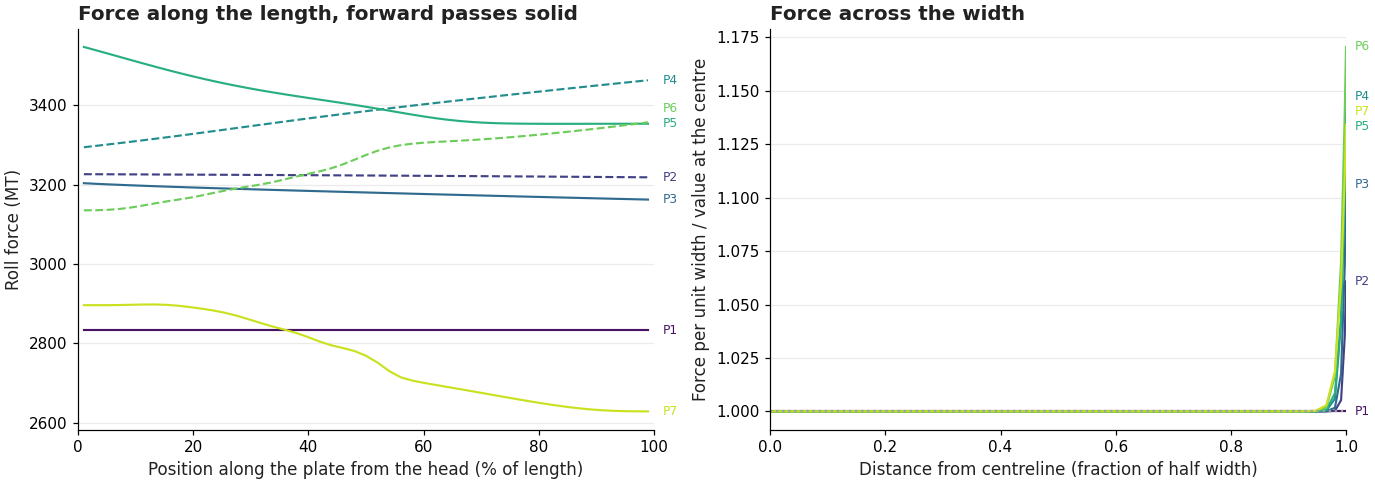

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
for k in range(N):
    ax[0].plot(100 * S["frac"], PR[k]["FL"], color=PCOL[k], lw=1.4, ls="-" if PS[k]["fwd"] else "--")
ax[0].set_xlabel("Position along the plate from the head (% of length)")
ax[0].set_ylabel("Roll force (MT)")
ax[0].set_title("Force along the length, forward passes solid")
ax[0].set_xlim(0, 100)
series_labels(ax[0], [(100.0, PR[k]["FL"][-1], f"P{k + 1}", PCOL[k]) for k in range(N)])
for k in range(N):
    yfr = S["yfrac"]
    ax[1].plot(yfr, PR[k]["oW"]["Fp"] / PR[k]["oW"]["Fp"][0], color=PCOL[k], lw=1.4)
ax[1].axhline(1, color=MUTED, ls=":")
ax[1].set_xlabel("Distance from centreline (fraction of half width)")
ax[1].set_ylabel("Force per unit width / value at the centre")
ax[1].set_title("Force across the width")
ax[1].set_xlim(0, 1)
series_labels(ax[1], [(1.0, PR[k]["oW"]["Fp"][-1] / PR[k]["oW"]["Fp"][0], f"P{k + 1}", PCOL[k]) for k in range(N)])
plt.show()

In the left panel the solid lines of forward passes and the dashed lines of reverse passes lean in different directions, which is the signature of the reversing sequence: the part of the plate that waited longest before a pass is the part that meets the roll last or first depending on direction. The spread along the length is small compared with the force itself but it changes the strain state, which is why the recrystallization maps later in this notebook also vary along the length. In the right panel the lift near the edge is confined to the outer few percent of the half width, because that is as far as the side face cooling has reached.

In [31]:
edge = np.array([PR[k]["oW"]["Fp"][-1] / PR[k]["oW"]["Fp"][0] for k in range(N)])
slope = np.array([PR[k]["FL"][-1] - PR[k]["FL"][0] for k in range(N)])
display(Markdown(
    f"The edge carries {100 * (edge.max() - 1):.1f}% more force per unit width than the centre at most (pass {int(np.argmax(edge)) + 1}). "
    f"Tail minus head force changes sign with direction: forward passes give {np.mean(slope[::2]):.0f} MT on average, reverse passes give {np.mean(slope[1::2]) if N > 1 else float('nan'):.0f} MT."
))

The edge carries 17.0% more force per unit width than the centre at most (pass 6). Tail minus head force changes sign with direction: forward passes give -126 MT on average, reverse passes give 128 MT.

## Force intensity in T x L and T x W

Here we see the force intensity inside the plate itself. For three passes (the first, a middle one and the last) the top row is the flow stress in the roll bite wedge, T x L. The middle row is the roll pressure along the same arc, aligned with the wedge above it. The bottom row is the flow stress in the plate cross-section at the exit plane, T x W. The same colour scale is used within each row, so passes can be compared by eye.

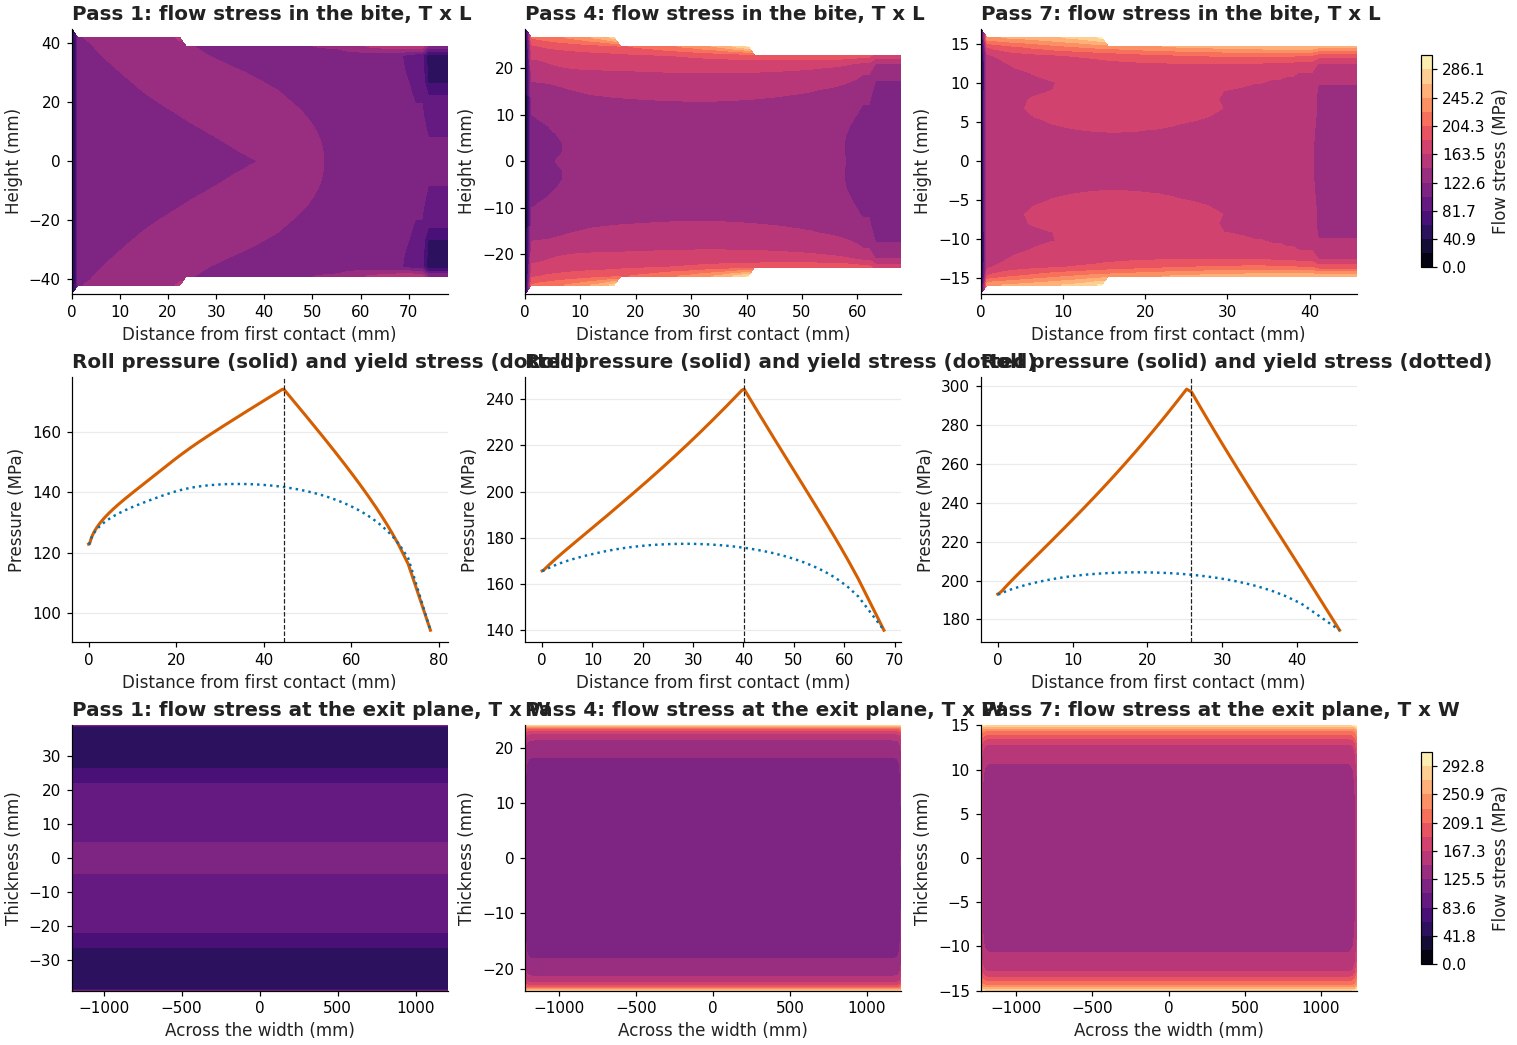

In [32]:
def wedge_scalar(geo, field, xi, nu=60, nzg=31):
    h, x = geo["h"], geo["x"]
    u_st = x[0] - x
    ug = np.linspace(0, x[0], nu)
    zg = np.linspace(-h[0] / 2, h[0] / 2, nzg)
    j = np.clip(np.searchsorted(u_st, ug), 0, len(h) - 1)
    out = np.full((nu, nzg), np.nan)
    for a, jj in enumerate(j):
        xin = zg / h[jj]
        ins = np.abs(xin) <= 0.5
        out[a, ins] = np.interp(xin[ins], xi, field[jj])
    return ug, zg, out

ns = len(SEL)
fig, axs = plt.subplots(3, ns, figsize=(4.6 * ns, 9.5), constrained_layout=True, squeeze=False)
smax = max(PR[k - 1]["oL"]["rec"]["sig"].max() for k in SEL)
wmax = max(PR[k - 1]["oW"]["sig_exit"].max() for k in SEL)
for c, kk in enumerate(SEL):
    k = kk - 1
    ps, pr = PS[k], PR[k]
    ug, zg, F_ = wedge_scalar(ps["geo"], pr["oL"]["rec"]["sig"], G.xi)
    im1 = axs[0, c].contourf(ug, zg, np.ma.masked_invalid(F_.T), levels=np.linspace(0, smax, 16), cmap="magma")
    axs[0, c].set_title(f"Pass {kk}: flow stress in the bite, T x L")
    axs[0, c].set_xlabel("Distance from first contact (mm)")
    axs[0, c].set_ylabel("Height (mm)")
    axs[0, c].grid(False)
    u_st = ps["geo"]["x"][0] - ps["geo"]["x"]
    axs[1, c].plot(u_st, pr["oL"]["p"][CM], color=ACCENT, lw=2)
    axs[1, c].plot(u_st, pr["oL"]["kp"][CM], color=PALETTE[0], ls=":", lw=1.6)
    nn = pr["oL"]["nn"][CM]
    axs[1, c].axvline(u_st[nn], color=INK, ls="--", lw=0.8)
    axs[1, c].set_xlabel("Distance from first contact (mm)")
    axs[1, c].set_ylabel("Pressure (MPa)")
    axs[1, c].set_title("Roll pressure (solid) and yield stress (dotted)")
    ymm = np.concatenate([-S["yfrac"][:0:-1], S["yfrac"]]) * ps["Wf"] / 2
    sw = np.concatenate([pr["oW"]["sig_exit"][:0:-1], pr["oW"]["sig_exit"]], axis=0)
    im3 = axs[2, c].contourf(ymm, G.xi * ps["hf"], sw.T, levels=np.linspace(0, wmax, 16), cmap="magma")
    axs[2, c].set_title(f"Pass {kk}: flow stress at the exit plane, T x W")
    axs[2, c].set_xlabel("Across the width (mm)")
    axs[2, c].set_ylabel("Thickness (mm)")
    axs[2, c].grid(False)
fig.colorbar(im1, ax=axs[0, :], shrink=0.8, label="Flow stress (MPa)")
fig.colorbar(im3, ax=axs[2, :], shrink=0.8, label="Flow stress (MPa)")
plt.show()

In the top row the wedge is darkest near the faces, where the strain rate is high and the skin is cold, and lightest in the interior. In the middle row the pressure curve sits above the dotted yield curve everywhere, and the dashed line marks the neutral point. In the bottom row the plate cross-section shows a bright rim at the faces and at the edge, where the material is colder and more strained, and a softer core. The stress contrast between rim and core is what the animation of the bite already hinted at.

## Temperature through the whole schedule

We now follow the temperature of the mid-length section from the first contact to the end of the hold after the last pass. The upper panel shows the surface, the quarter thickness and the core. The surface node reacts to everything: it drops at each descaling spray and roll contact, then recovers as heat flows out from the core. The ticks along the top mark the instant each pass meets the mid-length section. The lower panel shows the through-thickness gradient, which is the quantity that decides how uneven the structure is from face to core.

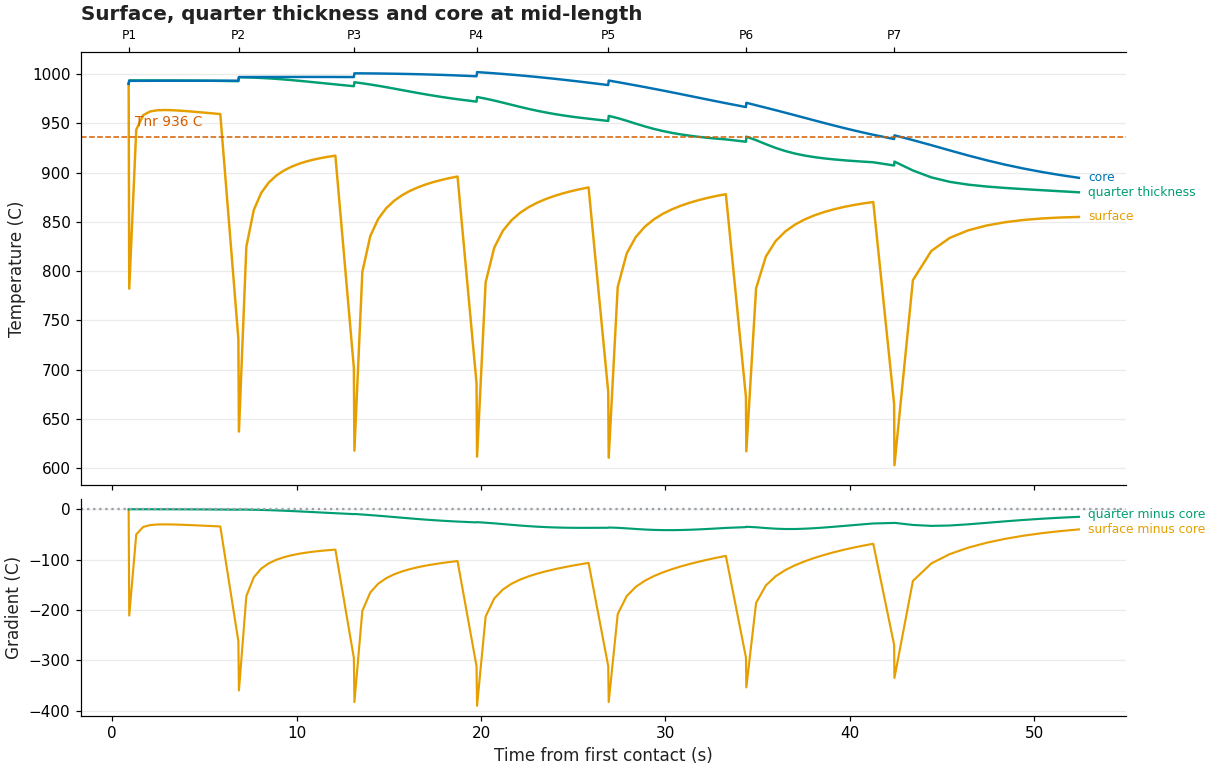

In [33]:
t_ax = S["recL"][0][CM]
T_ax = S["recL"][1][CM]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True, gridspec_kw=dict(height_ratios=[2, 1]))
series = [("surface", 0, PALETTE[1]), ("quarter thickness", IQ, PALETTE[2]), ("core", IC, PALETTE[0])]
for name, j, col in series:
    ax[0].plot(t_ax, T_ax[:, j], color=col, lw=1.6)
series_labels(ax[0], [(t_ax[-1], T_ax[-1, j], name, col) for name, j, col in series])
ax[0].axhline(TNR, color=ACCENT, ls="--", lw=1)
ax[0].annotate(f"Tnr {TNR:.0f} C", xy=(t_ax[0], TNR), xytext=(4, 5), textcoords="offset points", va="bottom", color=ACCENT, fontsize=9, annotation_clip=False)
top = ax[0].secondary_xaxis("top")
top.set_xticks([0.5 * (PS[k]["t_in"][CM] + PS[k]["t_out"][CM]) for k in range(N)])
top.set_xticklabels([f"P{k + 1}" for k in range(N)], fontsize=8)
ax[0].set_ylabel("Temperature (C)")
ax[0].set_title("Surface, quarter thickness and core at mid-length")
ax[1].plot(t_ax, T_ax[:, 0] - T_ax[:, IC], color=PALETTE[1], lw=1.4)
ax[1].plot(t_ax, T_ax[:, IQ] - T_ax[:, IC], color=PALETTE[2], lw=1.4)
ax[1].axhline(0, color=MUTED, ls=":")
series_labels(ax[1], [(t_ax[-1], (T_ax[:, 0] - T_ax[:, IC])[-1], "surface minus core", PALETTE[1]), (t_ax[-1], (T_ax[:, IQ] - T_ax[:, IC])[-1], "quarter minus core", PALETTE[2])])
ax[1].set_xlabel("Time from first contact (s)")
ax[1].set_ylabel("Gradient (C)")
plt.show()

The core line is smooth: it loses heat slowly to the surface and gains a few degrees at every bite from adiabatic heating. The surface line is the opposite, with a sharp drop at each descaling and roll contact followed by a recovery. The recovery is the heat conducted out from the core, which is why the lower panel shows a gradient that grows at every pass and then relaxes during the wait. When the core line crosses the dashed Tnr line the plate has entered the regime where static recrystallization is too slow to reset the grains between passes.

In [34]:
cross = next((k + 1 for k in range(N) if G.mean(PR[k]["TLin"])[CM] < TNR), None)
gr = T_ax[:, 0] - T_ax[:, IC]
display(Markdown(
    f"The core enters the schedule at {T_FIRST:.0f} C and leaves the last pass at {T_ax[np.searchsorted(t_ax, PS[-1]['t_out'][CM]), IC]:.0f} C. "
    f"The mean through-thickness temperature first drops below Tnr at the entry of pass {cross if cross else 'none'}. "
    f"The largest surface to core gap is {np.abs(gr).max():.0f} C and the largest quarter to core gap is {np.abs(T_ax[:, IQ] - T_ax[:, IC]).max():.0f} C."
))

The core enters the schedule at 990 C and leaves the last pass at 938 C. The mean through-thickness temperature first drops below Tnr at the entry of pass 5. The largest surface to core gap is 390 C and the largest quarter to core gap is 41 C.

## Where the heat comes from and where it goes

The temperature history above is the sum of heat sources and sinks. In every pass the plastic work adds adiabatic heat and the friction at the roll surface adds a little more. The roll contact takes heat out, and between passes the faces lose heat to the air and to the descaling spray. The left panel stacks these terms for each pass. Heat gained is above the axis, heat lost is below, and the dot is the net change from entering one pass to entering the next. The right panel accumulates the same terms from the first pass to the last, which is the build-up of adiabatic heat the schedule has to carry.

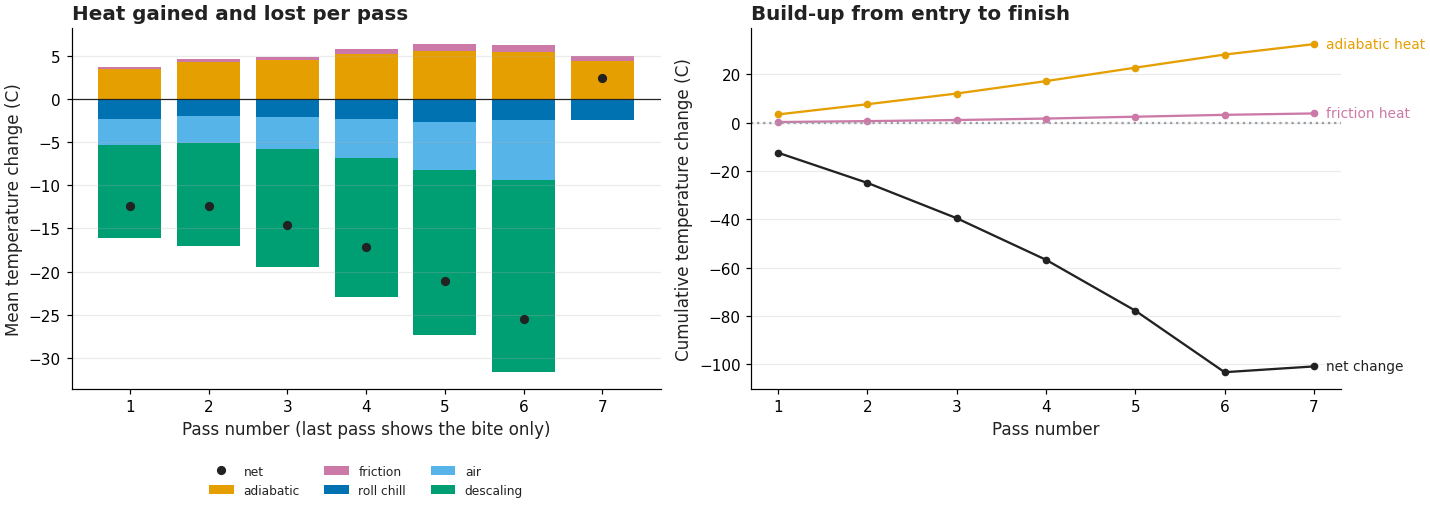

In [35]:
ad = np.array([PR[k]["oL"]["ad"][CM] for k in range(N)])
fr_ = np.array([PR[k]["oL"]["fr"][CM] for k in range(N)])
tin_m = np.array([G.mean(PR[k]["TLin"])[CM] for k in range(N)])
tout_m = np.array([G.mean(PR[k]["TLexit"])[CM] for k in range(N)])
roll = -(ad + fr_ - (tout_m - tin_m))
air = np.array([PR[k]["Tm_pre"][CM] - tout_m[k] if k < N - 1 else 0.0 for k in range(N)])
desc = np.array([PR[k]["Tm_post"][CM] - PR[k]["Tm_pre"][CM] if k < N - 1 else 0.0 for k in range(N)])
net = ad + fr_ + roll + air + desc
ks = np.arange(1, N + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
bot_pos = np.zeros(N)
bot_neg = np.zeros(N)
for lab, v, col in [("adiabatic", ad, PALETTE[1]), ("friction", fr_, PALETTE[3])]:
    ax[0].bar(ks, v, bottom=bot_pos, color=col, label=lab)
    bot_pos += v
for lab, v, col in [("roll chill", roll, PALETTE[0]), ("air", air, PALETTE[4]), ("descaling", desc, PALETTE[2])]:
    ax[0].bar(ks, v, bottom=bot_neg, color=col, label=lab)
    bot_neg += v
ax[0].plot(ks, net, "o", color=INK, ms=5, label="net")
ax[0].axhline(0, color=INK, lw=0.8)
ax[0].legend(frameon=False, ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax[0].set_xlabel("Pass number (last pass shows the bite only)")
ax[0].set_ylabel("Mean temperature change (C)")
ax[0].set_title("Heat gained and lost per pass")

for lab, v, col in [("adiabatic heat", ad, PALETTE[1]), ("friction heat", fr_, PALETTE[3]), ("net change", net, INK)]:
    ax[1].plot(ks, np.cumsum(v), "-o", color=col, ms=4)
    ax[1].annotate(lab, xy=(N, np.cumsum(v)[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=col, fontsize=9, annotation_clip=False)
ax[1].axhline(0, color=MUTED, ls=":")
ax[1].set_xlabel("Pass number")
ax[1].set_ylabel("Cumulative temperature change (C)")
ax[1].set_title("Build-up from entry to finish")
plt.show()

The stacked bars show that adiabatic heating grows as the passes get lighter in thickness but heavier in flow stress, because the same work is spread over less metal. Roll chill and the air loss together overtake it at most passes, which is why the net dot sits below zero for the early passes. The cumulative panel puts the numbers side by side: the heat the deformation adds over the whole schedule and the net cooling the plate still experiences despite that heat.

In [36]:
display(Markdown(
    f"Adiabatic heating adds {ad.sum():.0f} C to the mean temperature across {N} passes, with a per-pass range of {ad.min():.1f} to {ad.max():.1f} C. "
    f"Friction adds {fr_.sum():.1f} C. Roll chill removes {-roll.sum():.0f} C, air removes {-air.sum():.0f} C and descaling removes {-desc.sum():.0f} C between passes. "
    f"The net change from the first entry to the entry of the last pass is {net[:-1].sum():.0f} C."
))

Adiabatic heating adds 32 C to the mean temperature across 7 passes, with a per-pass range of 3.4 to 5.6 C. Friction adds 3.8 C. Roll chill removes 16 C, air removes 27 C and descaling removes 94 C between passes. The net change from the first entry to the entry of the last pass is -103 C.

## Temperature right after each pass, in T x L and T x W

The last thermal view is the temperature field the plate carries out of the bite. The top row is the T x L section, with length measured from the head after the pass, and the bottom row is the T x W section at mid-length. These are the fields the next interpass will start from. The cold skin lines are the roll chill, the lighter core is the adiabatic heat, and the colder ends and edges are the places where the plate waited or radiated the longest.

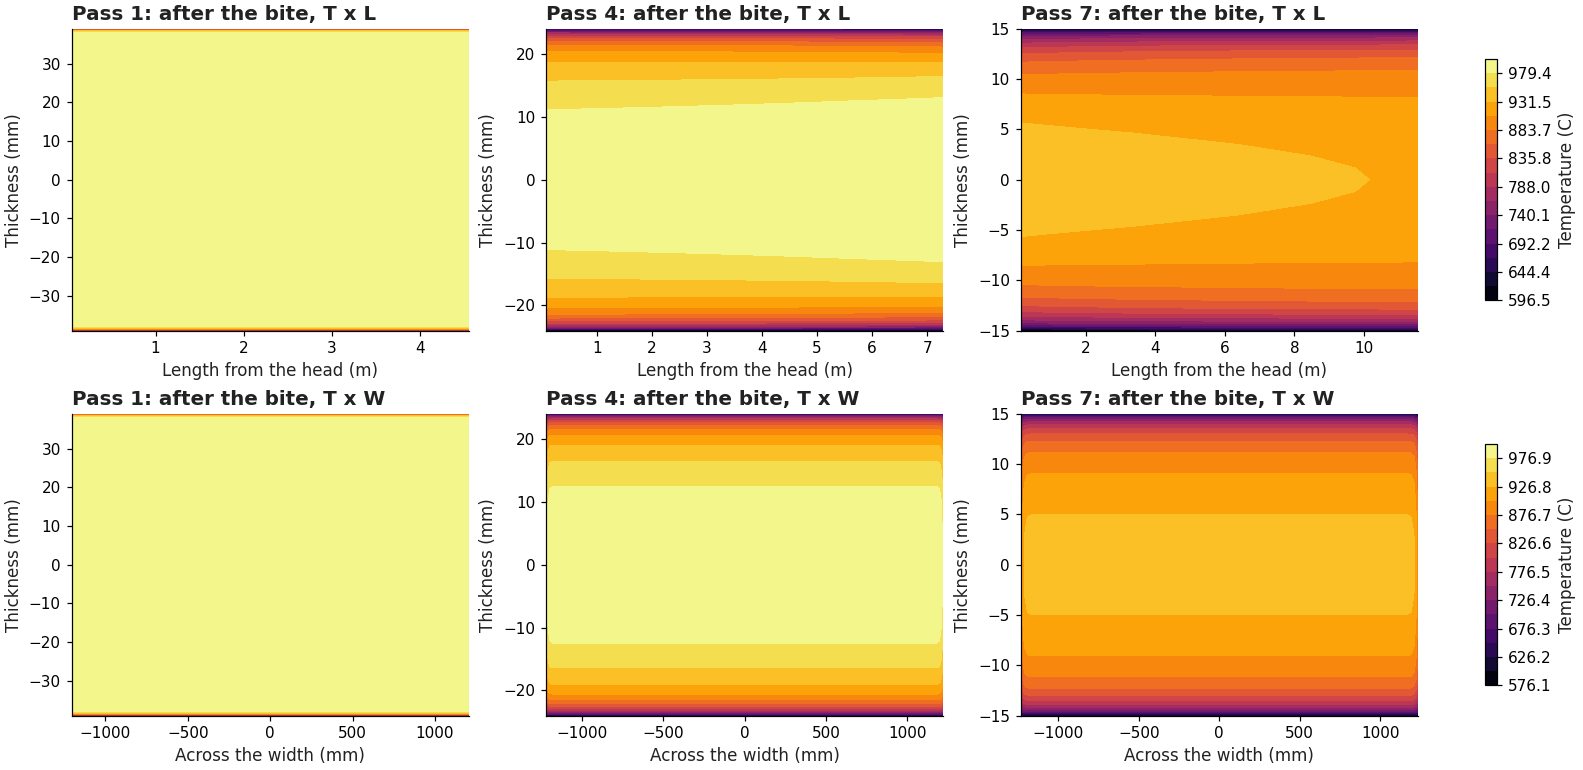

In [37]:
fig, axs = plt.subplots(2, ns, figsize=(4.8 * ns, 7), constrained_layout=True, squeeze=False)
tmin = min(PR[k - 1]["TLexit"].min() for k in SEL)
tmax = max(PR[k - 1]["TLexit"].max() for k in SEL)
tw_min = min(PR[k - 1]["TWexit"].min() for k in SEL)
tw_max = max(PR[k - 1]["TWexit"].max() for k in SEL)
for c, kk in enumerate(SEL):
    k = kk - 1
    ps, pr = PS[k], PR[k]
    xl = S["frac"] * ps["Lf"] / 1000
    im1 = axs[0, c].contourf(xl, G.xi * ps["hf"], pr["TLexit"].T, levels=np.linspace(tmin, tmax, 18), cmap="inferno")
    axs[0, c].set_title(f"Pass {kk}: after the bite, T x L")
    axs[0, c].set_xlabel("Length from the head (m)")
    axs[0, c].set_ylabel("Thickness (mm)")
    axs[0, c].grid(False)
    ymm = np.concatenate([-S["yfrac"][:0:-1], S["yfrac"]]) * ps["Wf"] / 2
    tw = np.concatenate([pr["TWexit"][:0:-1], pr["TWexit"]], axis=0)
    im2 = axs[1, c].contourf(ymm, G.xi * ps["hf"], tw.T, levels=np.linspace(tw_min, tw_max, 18), cmap="inferno")
    axs[1, c].set_title(f"Pass {kk}: after the bite, T x W")
    axs[1, c].set_xlabel("Across the width (mm)")
    axs[1, c].set_ylabel("Thickness (mm)")
    axs[1, c].grid(False)
fig.colorbar(im1, ax=axs[0, :], shrink=0.8, label="Temperature (C)")
fig.colorbar(im2, ax=axs[1, :], shrink=0.8, label="Temperature (C)")
plt.show()

Reading the top row from left to right, the skin lines get thinner as the plate gets thinner while the contrast between skin and core stays visible. Along the length the colour shifts slowly, because the head and tail waited different times before the pass. In the bottom row the edge is visibly colder than the centre, and the cold zone is only a few percent of the half width wide. These two patterns, one along the length and one across the width, are the temperature inhomogeneities that the final plate inherits.

In [38]:
k_l = SEL[-1] - 1
head_tail = PR[k_l]["TLexit"].mean(axis=1)
edge_gap = PR[k_l]["TWexit"][0].mean() - PR[k_l]["TWexit"][-1].mean()
display(Markdown(
    f"After the last pass the mean temperature runs from {head_tail[0]:.0f} C at the head to {head_tail[-1]:.0f} C at the tail, a gap of {abs(head_tail[0] - head_tail[-1]):.1f} C. "
    f"The edge of the mid-length section is {edge_gap:.1f} C colder than its centreline."
))

After the last pass the mean temperature runs from 834 C at the head to 835 C at the tail, a gap of 0.6 C. The edge of the mid-length section is 45.9 C colder than its centreline.

## Recrystallization state after every pass

Temperature and strain now meet. For each node of the section we know the strain it received, the temperature it kept during the wait, and the time it had. The recrystallization model turns these into four quantities: the dynamic fraction $X_d$ reached during the pass (DRX), the static or metadynamic fraction reached between passes (SRX), the total softened fraction, and the strain carried into the next pass. We then label each node. NRX means less than 5% softened, so all the strain is stored. PRX means between 5% and 95%. SRX means at least 95%, with the grains reset. We report three places through the thickness: the surface (a node 0.6% of the thickness below the face, because the face itself is only a skin), the quarter thickness and the core.

In [39]:
REG = ["NRX", "PRX", "SRX"]
RCOL = ["#0072b2", "#e69f00", "#009e73"]
nodes = [("surface", IS), ("quarter", IQ), ("core", IC)]

def regime(xtot, xd):
    base = REG[int(2 if xtot >= 0.95 else (1 if xtot >= 0.05 else 0))]
    return ("DRX+" + base) if xd >= 0.05 else base

rows = []
for k in range(N):
    f = PR[k]["fL"]
    ep = PR[k]["oL"]["eps_pass"]
    for nm, j in nodes:
        rows.append(dict(
            pass_no=k + 1, where=nm, T_in=PR[k]["TLin"][CM, j], strain_in_pass=ep[j],
            DRX_Xd=f["xd"][CM, j], static_X=f["xip"][CM, j], total_X=f["xtot"][CM, j],
            regime=regime(f["xtot"][CM, j], f["xd"][CM, j]), grain_um=f["d"][CM, j], strain_kept=f["eps_next"][CM, j],
        ))
RXT = pd.DataFrame(rows).set_index(["pass_no", "where"])
display(RXT.round(2))

T_in  strain_in_pass  DRX_Xd  ...  regime  grain_um strain_kept
pass_no where                                    ...                              
1       surface  990.00            0.17     0.0  ...     NRX     99.74        0.17
        quarter  990.00            0.17     0.0  ...     PRX     98.77        0.16
        core     990.00            0.15     0.0  ...     NRX     99.61        0.15
2       surface  788.31            0.18     0.0  ...     PRX     93.95        0.31
        quarter  992.70            0.18     0.0  ...     SRX     51.73        0.00
        core     993.16            0.16     0.0  ...     SRX     54.03        0.00
3       surface  749.49            0.19     0.0  ...     PRX     66.13        0.26
        quarter  987.60            0.19     0.0  ...     PRX     49.29        0.05
        core     996.89            0.18     0.0  ...     PRX     52.11        0.02
4       surface  726.47            0.20     0.0  ...     PRX     48.28        0.23
        quarter  971.93            0.20     0.0  ...     SRX     41.49        0.00
        core     997.68            0.19     0.0  ...     SRX     47.97        0.00
5       surface  711.67            0.21     0.0  ...     PRX     32.66        0.13
        quarter  952.36            0.21     0.0  ...     PRX     39.80        0.07
        core     988.76            0.21     0.0  ...     SRX     45.26        0.00
6       surface  700.61            0.19     0.0  ...     PRX     30.31        0.23
        quarter  931.30            0.19     0.0  ...     PRX     34.66        0.05
        core     966.44            0.19     0.0  ...     PRX     44.79        0.10
7       surface  689.46            0.15     0.0  ...     PRX     24.49        0.11
        quarter  907.18            0.14     0.0  ...     PRX     34.69        0.18
        core     934.01            0.14     0.0  ...     PRX     40.47        0.11

[21 rows x 8 columns]

The table is the numerical record of the regimes. Each row reads from left to right: the temperature at which the node entered the pass, the strain it received, how much DRX started during the pass, how much static softening followed, the total softened fraction, the label, the grain size after the wait and the strain that remains for the next pass. A node labelled with DRX in front has crossed the critical strain during the pass itself. In the next chart we look at the same information as a map through the thickness and as trends.

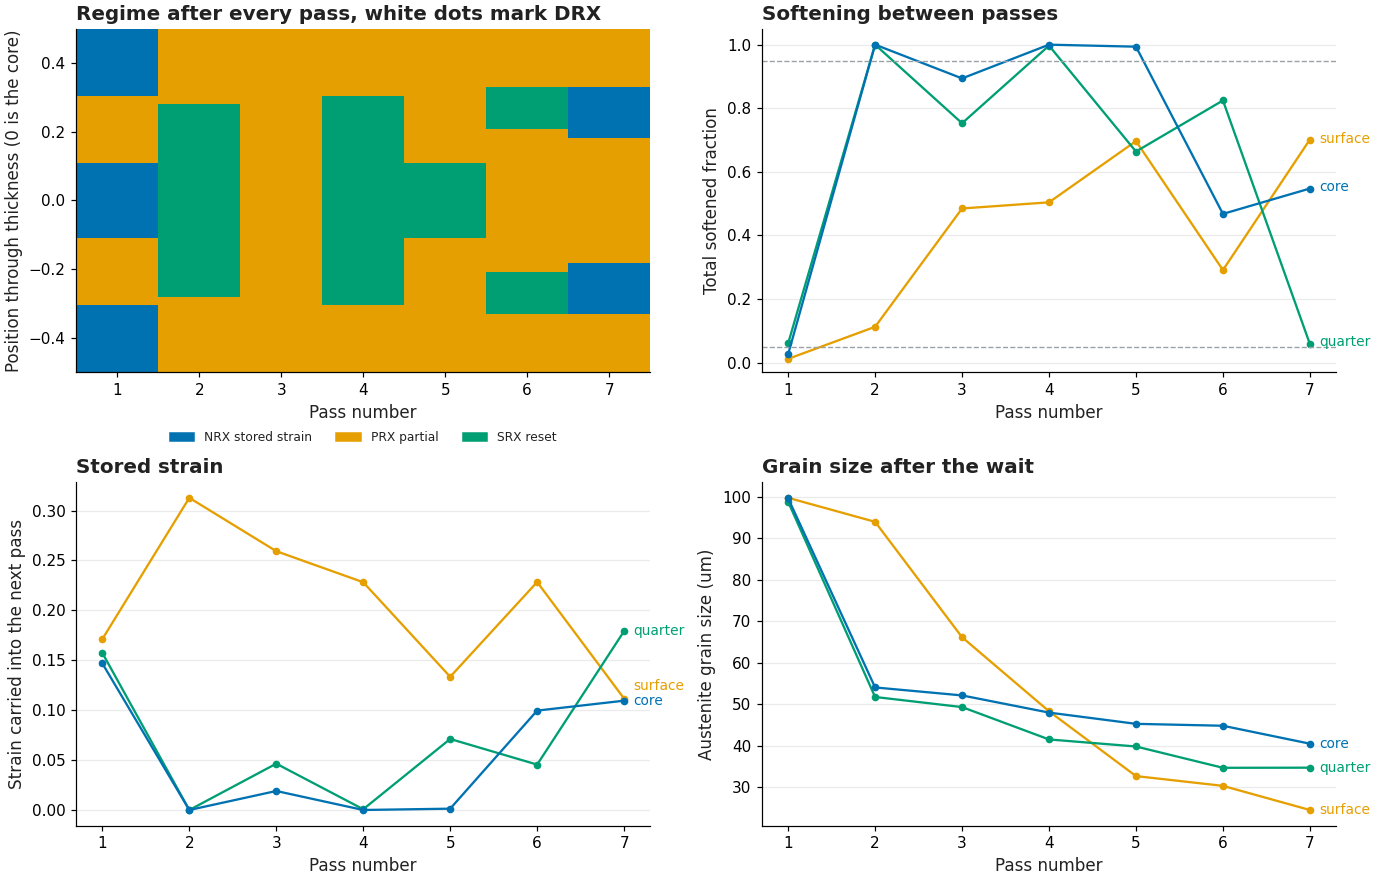

In [40]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 8), constrained_layout=True)
cmap_r = ListedColormap(RCOL)
nrm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)
cls_map = np.array([PR[k]["fL"]["cls"][CM] for k in range(N)]).T
xd_map = np.array([PR[k]["fL"]["xd"][CM] for k in range(N)]).T
ax[0, 0].pcolormesh(np.arange(1, N + 2) - 0.5, np.linspace(-0.5, 0.5, G.nz + 1), cls_map, cmap=cmap_r, norm=nrm)
yy, xx = np.where(xd_map >= 0.05)
ax[0, 0].plot(xx + 1, np.linspace(-0.5, 0.5, G.nz + 1)[yy] + 0.5 / G.nz, "o", color="white", ms=2.5)
ax[0, 0].set_xlabel("Pass number")
ax[0, 0].set_ylabel("Position through thickness (0 is the core)")
ax[0, 0].set_title("Regime after every pass, white dots mark DRX")
ax[0, 0].grid(False)
ax[0, 0].set_xticks(range(1, N + 1))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in RCOL]
ax[0, 0].legend(handles, ["NRX stored strain", "PRX partial", "SRX reset"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)

labels_by_panel = {ax[0, 1]: [], ax[1, 0]: [], ax[1, 1]: []}
for (nm, j), col in zip(nodes, [PALETTE[1], PALETTE[2], PALETTE[0]]):
    xt = [PR[k]["fL"]["xtot"][CM, j] for k in range(N)]
    kp = [PR[k]["fL"]["eps_next"][CM, j] for k in range(N)]
    dg = [PR[k]["fL"]["d"][CM, j] for k in range(N)]
    ax[0, 1].plot(ks, xt, "-o", color=col, ms=4)
    ax[1, 0].plot(ks, kp, "-o", color=col, ms=4)
    ax[1, 1].plot(ks, dg, "-o", color=col, ms=4)
    for a_, v_ in [(ax[0, 1], xt[-1]), (ax[1, 0], kp[-1]), (ax[1, 1], dg[-1])]:
        labels_by_panel[a_].append((N, v_, nm, col))
for a_, pts in labels_by_panel.items():
    series_labels(a_, pts, fontsize=9)
ax[0, 1].axhline(0.95, color=MUTED, ls="--", lw=0.9)
ax[0, 1].axhline(0.05, color=MUTED, ls="--", lw=0.9)
ax[0, 1].set_ylim(-0.03, 1.05)
ax[0, 1].set_xlabel("Pass number")
ax[0, 1].set_ylabel("Total softened fraction")
ax[0, 1].set_title("Softening between passes")
ax[1, 0].set_xlabel("Pass number")
ax[1, 0].set_ylabel("Strain carried into the next pass")
ax[1, 0].set_title("Stored strain")
ax[1, 1].set_xlabel("Pass number")
ax[1, 1].set_ylabel("Austenite grain size (um)")
ax[1, 1].set_title("Grain size after the wait")
plt.show()

The map in the upper left is the quickest way to see the schedule. A column that is green from face to core is a pass after which the austenite was fully reset. A column with amber or blue bands is a pass after which part of the thickness kept its strain, and the bands show where: the surface, which is coldest, usually leaves the green region first. The upper right chart gives the softened fraction at three depths against the 5% and 95% limits. The lower left chart shows the strain that survives into the next pass, and when it rises from pass to pass the plate is accumulating strain, which is the pancaking that TMCP aims for. The lower right chart shows the grain size, which falls where recrystallization repeatedly resets it and holds where it does not.

In [41]:
cnt = {r: int(sum(regime(PR[k]["fL"]["xtot"][CM, j], 0).endswith(r) for k in range(N) for _, j in nodes)) for r in REG}
n_drx = int(sum(PR[k]["fL"]["xd"][CM, j] >= 0.05 for k in range(N) for _, j in nodes))
kept = np.array([[PR[k]["fL"]["eps_next"][CM, j] for _, j in nodes] for k in range(N)])
d_all = np.array([[PR[k]["fL"]["d"][CM, j] for _, j in nodes] for k in range(N)])
display(Markdown(
    f"Of the {3 * N} labels (three depths, {N} passes), {cnt['SRX']} are SRX, {cnt['PRX']} are PRX and {cnt['NRX']} are NRX, and {n_drx} carry DRX. "
    f"The largest stored strain at the end of any pass is {kept.max():.2f}. "
    f"Core grain size moves from {P['d0']:.0f} um at first contact to {d_all[-1, 2]:.0f} um after the last pass, and the surface ends at {d_all[-1, 0]:.0f} um."
))

Of the 21 labels (three depths, 7 passes), 5 are SRX, 14 are PRX and 2 are NRX, and 0 carry DRX. The largest stored strain at the end of any pass is 0.31. Core grain size moves from 100 um at first contact to 40 um after the last pass, and the surface ends at 24 um.

## Regime maps in T x L and T x W

The same labels can be drawn over the whole section instead of three depths. The top row is the T x L section along the length, from the head, and the bottom row is the T x W section across the half width. The colours are the same three regimes. A band along one face means the surface layer behaved differently from the interior, and a patch near the head or tail means that end saw a different wait than the middle of the plate.

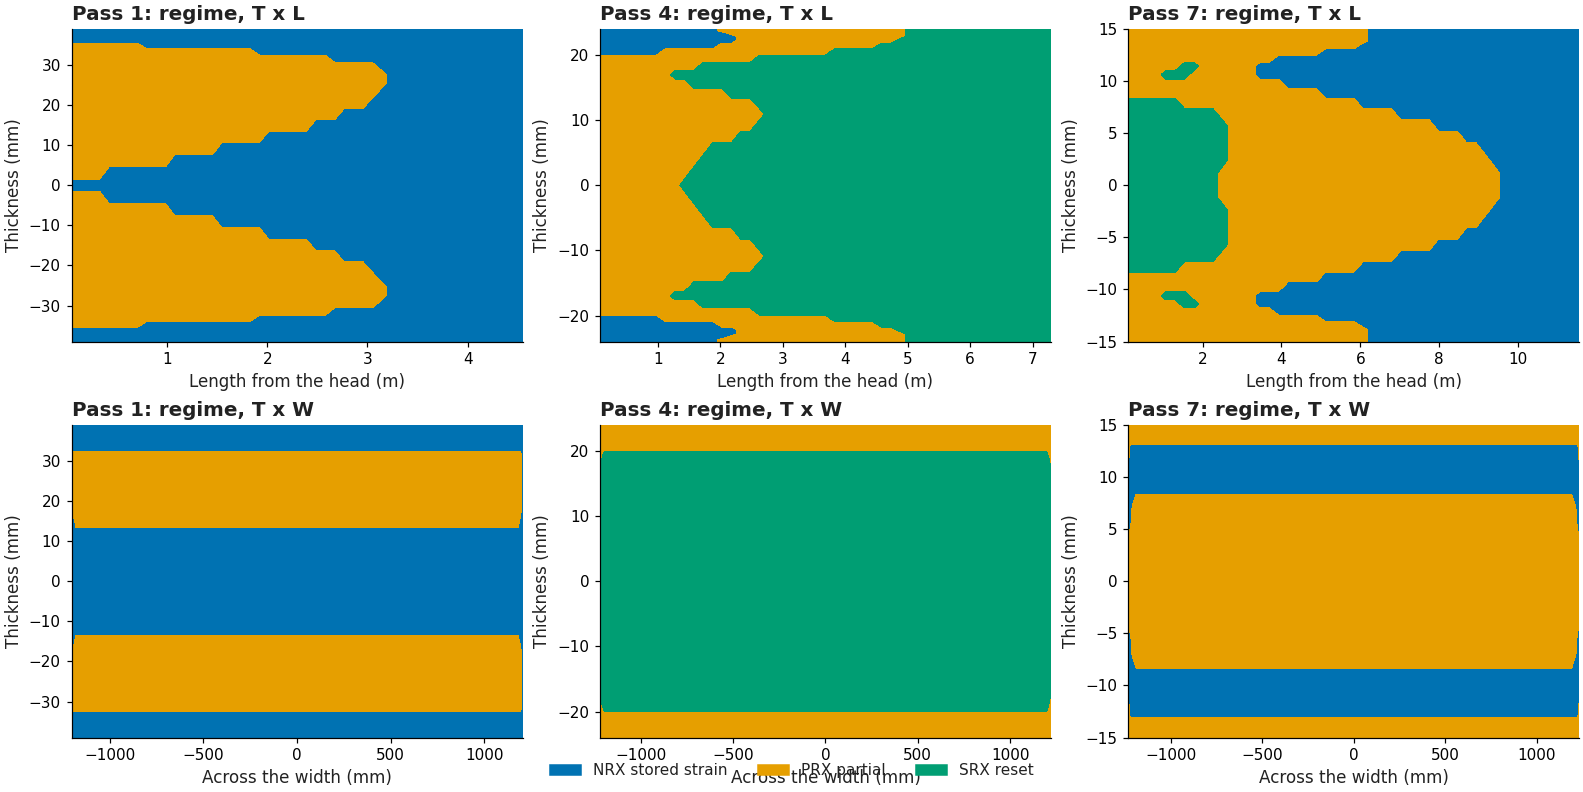

In [42]:
fig, axs = plt.subplots(2, ns, figsize=(4.8 * ns, 7.2), constrained_layout=True, squeeze=False)
for c, kk in enumerate(SEL):
    k = kk - 1
    ps, pr = PS[k], PR[k]
    xl = S["frac"] * ps["Lf"] / 1000
    axs[0, c].contourf(xl, G.xi * ps["hf"], pr["fL"]["cls"].T, levels=[-0.5, 0.5, 1.5, 2.5], colors=RCOL)
    axs[0, c].set_title(f"Pass {kk}: regime, T x L")
    axs[0, c].set_xlabel("Length from the head (m)")
    axs[0, c].set_ylabel("Thickness (mm)")
    axs[0, c].grid(False)
    ymm = np.concatenate([-S["yfrac"][:0:-1], S["yfrac"]]) * ps["Wf"] / 2
    cw = np.concatenate([pr["fW"]["cls"][:0:-1], pr["fW"]["cls"]], axis=0)
    axs[1, c].contourf(ymm, G.xi * ps["hf"], cw.T, levels=[-0.5, 0.5, 1.5, 2.5], colors=RCOL)
    axs[1, c].set_title(f"Pass {kk}: regime, T x W")
    axs[1, c].set_xlabel("Across the width (mm)")
    axs[1, c].set_ylabel("Thickness (mm)")
    axs[1, c].grid(False)
fig.legend(handles, ["NRX stored strain", "PRX partial", "SRX reset"], loc="lower center", ncol=3, frameon=False)
plt.show()

Where the map shows a uniform colour across the section the pass left the whole section in one state. The bands near the faces are the effect of descaling and roll chill, which put the surface layer on a different point of the softening curve than the core. The ends of the plate and the edges deserve a careful look: a colour change there means that the head, tail or edge ended the pass in a different regime from the body, and that difference is carried into the next pass as a difference in stored strain.

In [43]:
frac_non = [100 * float(np.mean(PR[k]["fL"]["cls"] < 2)) for k in range(N)]
frac_edge = [100 * float(np.mean(PR[k]["fW"]["cls"] < 2)) for k in range(N)]
display(Markdown(
    f"Share of the T x L section that is not fully reset after each pass: " + ", ".join(f"P{k + 1} {v:.0f}%" for k, v in enumerate(frac_non)) + ". "
    f"Share of the T x W section that is not fully reset: " + ", ".join(f"P{k + 1} {v:.0f}%" for k, v in enumerate(frac_edge)) + "."
))

Share of the T x L section that is not fully reset after each pass: P1 100%, P2 42%, P3 87%, P4 41%, P5 60%, P6 60%, P7 92%. Share of the T x W section that is not fully reset: P1 100%, P2 45%, P3 100%, P4 40%, P5 81%, P6 78%, P7 100%.

## The whole process, replayed in time

Finally we put the pieces on one screen and let time run. The top panel is the side view of the plate, T x L, in the mill frame: the roll sits at zero, the plate moves through it, and the temperature is coloured on the section. Vertical scale is exaggerated against the length. The lower left panel is the T x W cross-section at mid-length. The lower middle panel is the mid-length temperature history with a moving marker, and the lower right panel is the roll force along each pass with the same marker. Use the slider to step through the schedule or press play. The label at the slider gives the time and the pass.

Under the interactive figure are five stills of the same replay, spread across the whole schedule, drawn as plain images. The frame by frame picture is there whatever the viewer does with the animation's script, and the animation is also written to `rolling_outputs/process_timeline.html`, which plays in a browser.


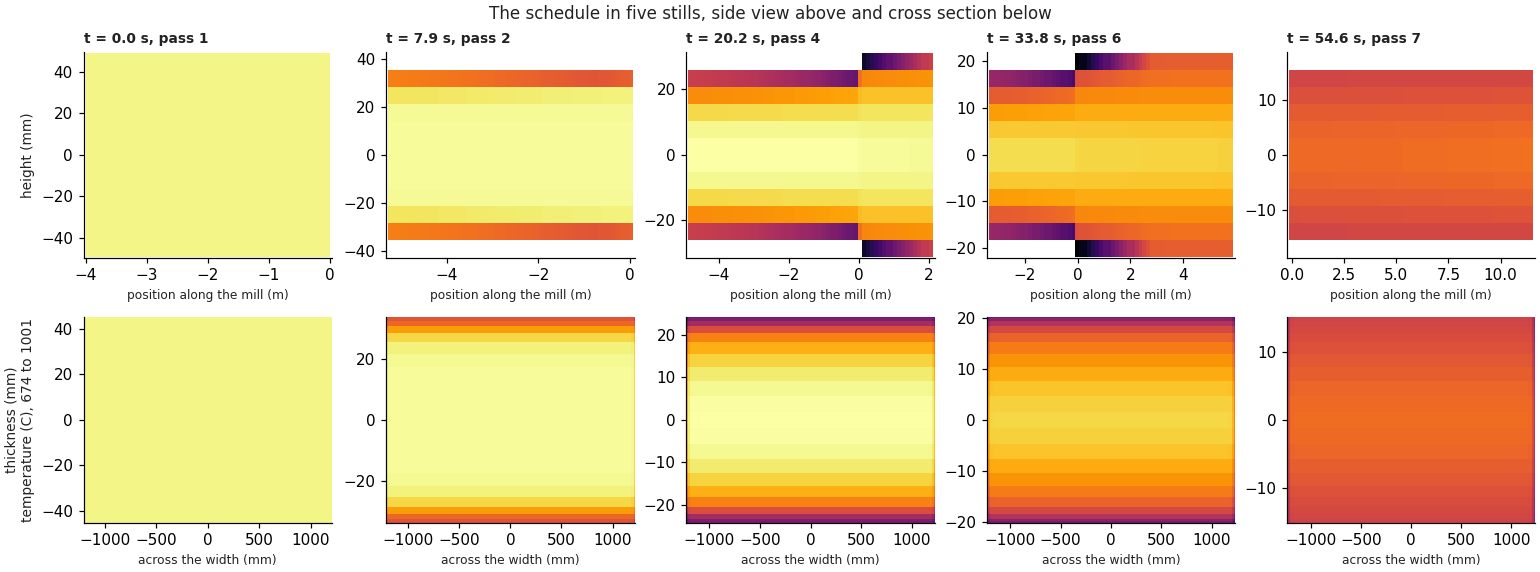

In [44]:
tL_all, TL_all, hL_all = S["recL"]
tW_all, TW_all, hW_all, WW_all = S["recW"]
starts = np.array([p["t_start"] for p in PS])

def interp_rec(t_arr, A, t):
    i = int(np.searchsorted(t_arr, t))
    if i <= 0:
        return A[0]
    if i >= len(t_arr):
        return A[-1]
    w = (t - t_arr[i - 1]) / max(t_arr[i] - t_arr[i - 1], 1e-9)
    return A[i - 1] * (1 - w) + A[i] * w

def side_state(t):
    k = max(int(np.searchsorted(starts, t, side="right")) - 1, 0)
    p = PS[k]
    te = min(max(t, p["t_start"]), p["t_end"])
    sg = 1.0 if p["fwd"] else -1.0
    tin, tout = p["t_in"], p["t_out"]
    x = np.where(te < tin, -sg * p["v_in"] * 1000 * (tin - te),
                 np.where(te > tout, sg * p["vf"] * 1000 * (te - tout), -sg * p["geo"]["x"][0] * (1 - (te - tin) / p["tau"])))
    hh = np.array([interp_rec(tL_all[c], hL_all[c], t) for c in range(S["nL"])])
    TT = np.array([interp_rec(tL_all[c], TL_all[c], t) for c in range(S["nL"])])
    return k, x, hh, TT

def side_image(t, nxp=64, nzp=12):
    k, x, hh, TT = side_state(t)
    order = np.argsort(x)
    xs, hs, Ts = x[order], hh[order], TT[order]
    dx = max(np.median(np.diff(xs)), 1.0)
    xp = np.linspace(xs[0] - dx, xs[-1] + dx, nxp)
    zg = np.linspace(-PS[k]["h0"] / 2, PS[k]["h0"] / 2, nzp)
    img = np.full((nzp, nxp), np.nan)
    idx = np.clip(np.searchsorted(xs, xp), 0, len(xs) - 1)
    idx2 = np.clip(idx - 1, 0, len(xs) - 1)
    near = np.where(np.abs(xs[idx] - xp) < np.abs(xs[idx2] - xp), idx, idx2)
    for a, c in enumerate(near):
        if abs(xs[c] - xp[a]) > 0.8 * dx + 1:
            continue
        xin = zg / hs[c]
        ins = np.abs(xin) <= 0.5
        img[ins, a] = np.interp(xin[ins], G.xi, Ts[c])
    return k, xp / 1000, zg, img

def cross_image(t):
    T2 = interp_rec(tW_all, TW_all, t)[::2]
    h_ = float(interp_rec(tW_all, hW_all, t))
    W_ = float(interp_rec(tW_all, WW_all, t))
    yf_c = S["yfrac"][::2]
    ymm = np.concatenate([-yf_c[:0:-1], yf_c]) * W_ / 2
    return ymm, (G.xi * h_)[::2], np.concatenate([T2[:0:-1], T2], axis=0).T[::2]

times = []
for k, p in enumerate(PS):
    times += list(np.linspace(p["t_start"], p["t_end"], 4)[:-1])
    nxt = PS[k + 1]["t_start"] if k < N - 1 else p["t_end"] + P["hold_after"]
    times += list(np.linspace(p["t_end"], nxt, 2)[:-1]) if k < N - 1 else list(np.linspace(p["t_end"], nxt, 3))
times = np.array(times)

tz_min, tz_max = float(np.percentile(TL_all, 0.5)), float(TL_all.max())
tt_c, TT_c = tL_all[CM], TL_all[CM]
f_t, f_F = [], []
for k in range(N):
    tm = 0.5 * (PS[k]["t_in"] + PS[k]["t_out"])
    o = np.argsort(tm)
    f_t += list(tm[o]) + [np.nan]
    f_F += list(PR[k]["FL"][o]) + [np.nan]
Fmax = float(np.nanmax(f_F)) * 1.08

fr_list, fr_names, fr_labels = [], [], []
for f_i, t in enumerate(times):
    k, xp, zg, img = side_image(t)
    ymm, zmm, T2 = cross_image(t)
    nm = f"t{f_i}"
    fr_list.append(go.Frame(name=nm, traces=[0, 1, 2, 3], data=[
        go.Heatmap(x=xp, y=zg, z=np.round(img, 0), zmin=tz_min, zmax=tz_max, colorscale="Inferno", showscale=False),
        go.Heatmap(x=ymm, y=zmm, z=np.round(T2, 0), zmin=tz_min, zmax=tz_max, colorscale="Inferno", showscale=False),
        go.Scatter(x=[t, t], y=[tz_min, tz_max], mode="lines", line=dict(color=INK, width=2)),
        go.Scatter(x=[t, t], y=[0, Fmax], mode="lines", line=dict(color=INK, width=2)),
    ], layout=go.Layout(xaxis=dict(range=[float(xp[0]), float(xp[-1])]), yaxis=dict(range=[-PS[k]["h0"] / 2 * 1.1, PS[k]["h0"] / 2 * 1.1]))))
    fr_names.append(nm)
    fr_labels.append(f"{t:.1f} s, pass {k + 1}")

fig = make_subplots(rows=2, cols=3, specs=[[{"colspan": 3}, None, None], [{}, {}, {}]], row_heights=[0.42, 0.58],
                    subplot_titles=("Side view T x L in the mill frame (thickness exaggerated)", "Cross-section T x W at mid-length", "Mid-length temperature (C)", "Roll force during each pass (MT)"),
                    horizontal_spacing=0.08, vertical_spacing=0.2)
d0_ = fr_list[0].data
fig.add_trace(go.Heatmap(d0_[0], colorbar=dict(x=1.01, y=0.8, len=0.35, thickness=10, title="C")), row=1, col=1)
fig.add_trace(go.Heatmap(d0_[1]), row=2, col=1)
fig.add_trace(d0_[2], row=2, col=2)
fig.add_trace(d0_[3], row=2, col=3)
for (nm, j, col) in series:
    fig.add_trace(go.Scatter(x=tt_c, y=TT_c[:, j], mode="lines", line=dict(color=col, width=1.6), name=nm), row=2, col=2)
fig.add_trace(go.Scatter(x=[tt_c[0], tt_c[-1]], y=[TNR, TNR], mode="lines", line=dict(color=ACCENT, dash="dash", width=1), name="Tnr"), row=2, col=2)
fig.add_trace(go.Scatter(x=f_t, y=f_F, mode="lines", line=dict(color=PALETTE[0], width=1.6), name="force"), row=2, col=3)
fig.update_xaxes(title_text="Position along the mill (m)", row=1, col=1)
fig.update_yaxes(title_text="Height (mm)", row=1, col=1)
fig.update_xaxes(title_text="Across the width (mm)", row=2, col=1)
fig.update_yaxes(title_text="Thickness (mm)", row=2, col=1)
fig.update_xaxes(title_text="Time (s)", row=2, col=2)
fig.update_xaxes(title_text="Time (s)", row=2, col=3)
fig.update_layout(
    height=840, showlegend=False, margin=dict(l=60, r=80, t=80, b=170),
    updatemenus=[dict(type="buttons", x=0.0, y=-0.14, direction="left", buttons=[
        dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=140, redraw=True), fromcurrent=True)]),
        dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
    sliders=[dict(x=0.2, len=0.8, y=-0.14, currentvalue=dict(prefix="Time: "), steps=[
        dict(method="animate", label=lb, args=[[nm], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for nm, lb in zip(fr_names, fr_labels)])],
)
fig.frames = fr_list
slim(fig)
fig.write_html("rolling_outputs/process_timeline.html", include_plotlyjs="cdn")
fig.show()

# the same replay as five stills, spread across the whole schedule
pick_t = np.linspace(0, len(times) - 1, 5).astype(int)
panels_t = []
for q in pick_t:
    tq = float(times[q])
    kq, xp_q, zg_q, img_q = side_image(tq)
    ymm_q, zmm_q, T2_q = cross_image(tq)
    panels_t.append((tq, kq, xp_q, zg_q, img_q, ymm_q, zmm_q, T2_q))
T_lo_t = min(min(span_of(p[4], (tz_min, tz_max))[0], span_of(p[7], (tz_min, tz_max))[0])
             for p in panels_t)
T_hi_t = max(max(span_of(p[4], (tz_min, tz_max))[1], span_of(p[7], (tz_min, tz_max))[1])
             for p in panels_t)
fig, axs = plt.subplots(2, 5, figsize=(14.0, 5.2), constrained_layout=True, squeeze=False)
for c, (tq, kq, xp_q, zg_q, img_q, ymm_q, zmm_q, T2_q) in enumerate(panels_t):
    axs[0, c].pcolormesh(xp_q, zg_q, img_q, cmap="inferno", shading="auto",
                         vmin=T_lo_t, vmax=T_hi_t, rasterized=True)
    axs[1, c].pcolormesh(ymm_q, zmm_q, T2_q, cmap="inferno", shading="auto",
                         vmin=T_lo_t, vmax=T_hi_t, rasterized=True)
    axs[0, c].set_title(f"t = {tq:.1f} s, pass {kq + 1}", fontsize=9)
    axs[0, c].set_xlabel("position along the mill (m)", fontsize=8)
    axs[1, c].set_xlabel("across the width (mm)", fontsize=8)
    axs[0, c].set_xlim(float(xp_q[0]), float(xp_q[-1]))
    axs[0, c].set_ylim(-PS[kq]["h0"] / 2 * 1.1, PS[kq]["h0"] / 2 * 1.1)
    for r2 in (0, 1):
        axs[r2, c].grid(False)
axs[0, 0].set_ylabel("height (mm)", fontsize=9)
axs[1, 0].set_ylabel(f"thickness (mm)\ntemperature (C), {T_lo_t:.0f} to {T_hi_t:.0f}", fontsize=9)
fig.suptitle("The schedule in five stills, side view above and cross section below", fontsize=11)
plt.show()


Early in the replay the plate is short and thick and the side view shows a uniform section with a cold skin on both faces. As the passes go on, the plate stretches along the mill, the thickness step at the roll becomes visible, and the head and tail drift apart in temperature because each waits a different time. In the cross-section the edge colder band is present from the first pass and sharpens during every wait. In the two line panels the marker travels along the temperature history and across the force curve, so the force of a pass can be matched with the temperature of the same moment.

In [45]:
dur = [PS[k]["t_end"] - PS[k]["t_start"] for k in range(N)]
waits_mid = [PS[k + 1]["t_in"][CM] - PS[k]["t_out"][CM] for k in range(N - 1)]
display(Markdown(
    f"The schedule lasts {S['t_final']:.0f} s including a {P['hold_after']:.0f} s hold. Passes take {min(dur):.1f} to {max(dur):.1f} s each and the mid-length section waits {min(waits_mid):.1f} to {max(waits_mid):.1f} s between them. "
    f"The animation holds {len(times)} frames. Standalone copies of all three animations are saved in the rolling_outputs folder next to this notebook."
))

The schedule lasts 55 s including a 10 s hold. Passes take 1.8 to 4.5 s each and the mid-length section waits 5.9 to 8.0 s between them. The animation holds 30 frames. Standalone copies of all three animations are saved in the rolling_outputs folder next to this notebook.

## What we found

We close by reading the schedule back in numbers. The cell below recomputes every figure from the results above, so it stays correct when the inputs change.

In [46]:
k_cold = int(np.argmax([PR[k]["oL"]["rec"]["T"][-1][0] * -1 for k in range(N)]))
lines = [
    f"Roll force at mid-length goes from {fm.min():.0f} MT (pass {int(np.argmin(fm)) + 1}) to {fm.max():.0f} MT (pass {int(np.argmax(fm)) + 1}), with a peak drive power of {pw.max() / 1e3:.1f} MW.",
    f"Deformation reaches the core by the end of the arc in {len([k for k in range(N) if PEN[k][-1] >= 0.999])} of {N} passes, and core strain is {min(cr):.2f} to {max(cr):.2f} of the surface strain.",
    f"Adiabatic heating adds {ad.sum():.0f} C over the schedule, but roll chill, air and descaling remove {-(roll + air + desc).sum():.0f} C, so the net change before the last pass is {net[:-1].sum():.0f} C.",
    f"The surface skin drops as low as {min(pr['oL']['rec']['T'][-1][0] for pr in PR):.0f} C at the bite exit, while the core never leaves the range {T_ax[:, IC].min():.0f} to {T_ax[:, IC].max():.0f} C.",
    f"Static or metadynamic softening completes at {cnt['SRX']} of {3 * N} depth and pass combinations, is partial at {cnt['PRX']} and does not start at {cnt['NRX']}.",
    f"The plate ends {PS[-1]['hf']:.0f} mm thick, {PS[-1]['Wf']:.0f} mm wide and {PS[-1]['Lf'] / 1000:.1f} m long, with a mean temperature of {G.mean(PR[-1]['TLexit'])[CM]:.0f} C leaving the last pass.",
]
display(Markdown("\n".join(f"{i + 1}. {s}" for i, s in enumerate(lines))))

1. Roll force at mid-length goes from 2769 MT (pass 7) to 3397 MT (pass 5), with a peak drive power of 12.1 MW.
2. Deformation reaches the core by the end of the arc in 0 of 7 passes, and core strain is 0.87 to 0.98 of the surface strain.
3. Adiabatic heating adds 32 C over the schedule, but roll chill, air and descaling remove 137 C, so the net change before the last pass is -103 C.
4. The surface skin drops as low as 603 C at the bite exit, while the core never leaves the range 895 to 1002 C.
5. Static or metadynamic softening completes at 5 of 21 depth and pass combinations, is partial at 14 and does not start at 2.
6. The plate ends 30 mm thick, 2468 mm wide and 11.7 m long, with a mean temperature of 889 C leaving the last pass.

## What we could not tell

The model is physical but it is not calibrated to one mill. Twelve limits matter when we read the numbers.

1. The flow stress, DRX and static softening constants come from the C-Mn and Nb-bearing tables of the literature rather than from this grade. They fix the shape of the results but not the absolute force. Put the C-Mn base constants in place of the set used here and the peak stress falls about 10 per cent at these temperatures and rates. A single plant force measurement per pass would let us scale them.
2. The through-thickness strain profile uses a penetration law with one adjustable constant, `kappa`, not a finite element solution. It captures the trend with the shape factor but not the local shear bands.
3. Lateral spread uses a simple coefficient (`spread_k`) and the edge region has the same strain state as the centre. Real edges see plane stress and a different strain.
4. Heat transfer coefficients for roll contact and descaling are single values. Water film and scale thickness would change them from pass to pass. The roll contact value sits inside the range measured on a pilot mill. The descaling value is this notebook's own: published descaling coefficients are identified mill by mill and do not transfer.
5. The mill is treated as rigid apart from the gap setting through the mill modulus. Roll bending and crown are not modelled, so the force is uniform in the sense of a flat roll gap.
6. Length columns do not conduct heat along the length, which is a good assumption for the speeds used here but not for a plate left at rest for long.
7. PRX and NRX are defined by the softened fraction at 5% and 95%. A different threshold would move some labels.
8. The critical strain for DRX follows the form of Sellars with the Nb factor this grade adds, and the Nb coefficient is a literature choice. Halving it or changing the grain size exponent moves the critical strain by a factor of two, and with it which passes carry DRX. The same coefficient is used for the peak strain in some sources, where reading it that way would make the critical strain used here 25 per cent high.
9. The sticking limit is one fraction of the plane strain yield, not a function of temperature, scale or lubrication.
10. The DRX grain size uses the coefficient set for microalloyed steel. With the critical strain of this grade no pass reaches DRX, so the label only matters if a heavier draft is entered.
11. The emissivity of the plate and the fraction of the plastic work that becomes heat are single values. Measurements put that fraction below the 0.9 used here and varying with the material and the rate.
12. Static softening runs with an Avrami exponent of 2, the top of the range of 1 to 2 published for it, which softens the austenite faster between passes than an exponent of 1 would.

## What we do next

Three follow-ups come straight out of the results. First, compare the predicted force of each pass with the measured force from the mill and rescale the flow stress constants until they agree, then re-read the recrystallization maps. Second, add a hold on the table between two passes, which is how TMCP schedules reach the non-recrystallization range, and test how much waiting time moves the last passes from PRX to NRX. Third, couple the last pass temperature field to the accelerated cooling notebook so that the through-thickness gradient we see here becomes the starting condition for the laminar cooling model.